# BÀI TẬP LỚN HỌC MÁY - BÁO CÁO MILESTONE 1
## 01. Phân Tích Dữ Liệu Khám Phá (EDA) & Thiết Kế Pipeline Tiền Xử Lý Chống Data Leakage
---
- **Bộ dữ liệu:** Framingham Heart Study (`data/framingham.csv`)
- **Mục tiêu:** Sàng lọc & Dự báo nguy cơ mắc bệnh tim mạch vành trong 10 năm (`TenYearCHD`)
- **Thành viên phụ trách:** Thành viên 1 (Nhóm trưởng) & Thành viên 3
- **Mốc chấm:** Milestone 1 (Checkpoint Buổi 4) - Bám sát Nhiệm vụ STT 1, 3, 4, 5 trong Bảng Phân Công

In [58]:
# 1. Import các thư viện phân tích và hệ thống
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thêm thư mục gốc vào sys.path để import trực tiếp từ src
sys.path.append(os.path.abspath('..'))
from src.features import (
    create_features,
    get_preprocessor_pipeline,
    load_and_split_data,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
    TARGET_COLUMN
)

# Cấu hình giao diện biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
print('Imports và cấu hình thành công!')

Imports và cấu hình thành công!


## 1. Tải Dữ Liệu & Kiểm Tra Cấu Trúc Tổng Quát
Sử dụng đường dẫn tương đối chuẩn `../data/framingham.csv` theo quy ước của nhóm.

In [ ]:
df = pd.read_csv('../data/framingham.csv')
print(f'Kích thước bộ dữ liệu ban đầu: {df.shape[0]} dòng x {df.shape[1]} cột')
df.head()

Kích thước bộ dữ liệu ban đầu: 4240 dòng x 16 cột


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


: 

: 

In [ ]:
# Thống kê mô tả các biến số
df.describe().T

,count,mean,std,min,25%,50%,75%,max
male,4240.0,0.429245,0.495027,0.00,0.00,0.0,1.00,1.0
age,4240.0,49.580189,8.572942,32.00,42.00,49.0,56.00,70.0
education,4135.0,1.979444,1.019791,1.00,1.00,2.0,3.00,4.0
currentSmoker,4240.0,0.494104,0.500024,0.00,0.00,0.0,1.00,1.0
cigsPerDay,4211.0,9.005937,11.922462,0.00,0.00,0.0,20.00,70.0
BPMeds,4187.0,0.029615,0.169544,0.00,0.00,0.0,0.00,1.0
prevalentStroke,4240.0,0.005896,0.076569,0.00,0.00,0.0,0.00,1.0
prevalentHyp,4240.0,0.310613,0.462799,0.00,0.00,0.0,1.00,1.0
diabetes,4240.0,0.025708,0.158280,0.00,0.00,0.0,0.00,1.0
totChol,4190.0,236.699523,44.591284,107.00,206.00,234.0,263.00,696.0


: 

: 

## 2. Kiểm Tra Dữ Liệu Thiếu (Missing Values)
Phát hiện các cột có dữ liệu thiếu để thiết kế chiến lược điền khuyết (Imputation) phù hợp.

In [ ]:
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Số lượng khuyết': missing, 'Tỷ lệ (%)': missing_pct})
missing_df = missing_df[missing_df['Số lượng khuyết'] > 0].sort_values('Số lượng khuyết', ascending=False)

print(f'Tổng số giá trị bị khuyết: {df.isnull().sum().sum()}')
print(f'Số lượng cột bị khuyết: {len(missing_df)} / {df.shape[1]}')
missing_df

Tổng số giá trị bị khuyết: 645
Số lượng cột bị khuyết: 7 / 16


,Số lượng khuyết,Tỷ lệ (%)
glucose,388,9.15
education,105,2.48
BPMeds,53,1.25
totChol,50,1.18
cigsPerDay,29,0.68
BMI,19,0.45
heartRate,1,0.02


: 

: 

## 3. Trực Quan Hóa Dữ Liệu Khám Phá (EDA)
Phân tích phân phối lớp mục tiêu `TenYearCHD`, các biến số lâm sàng và mối tương quan giữa các đặc trưng.

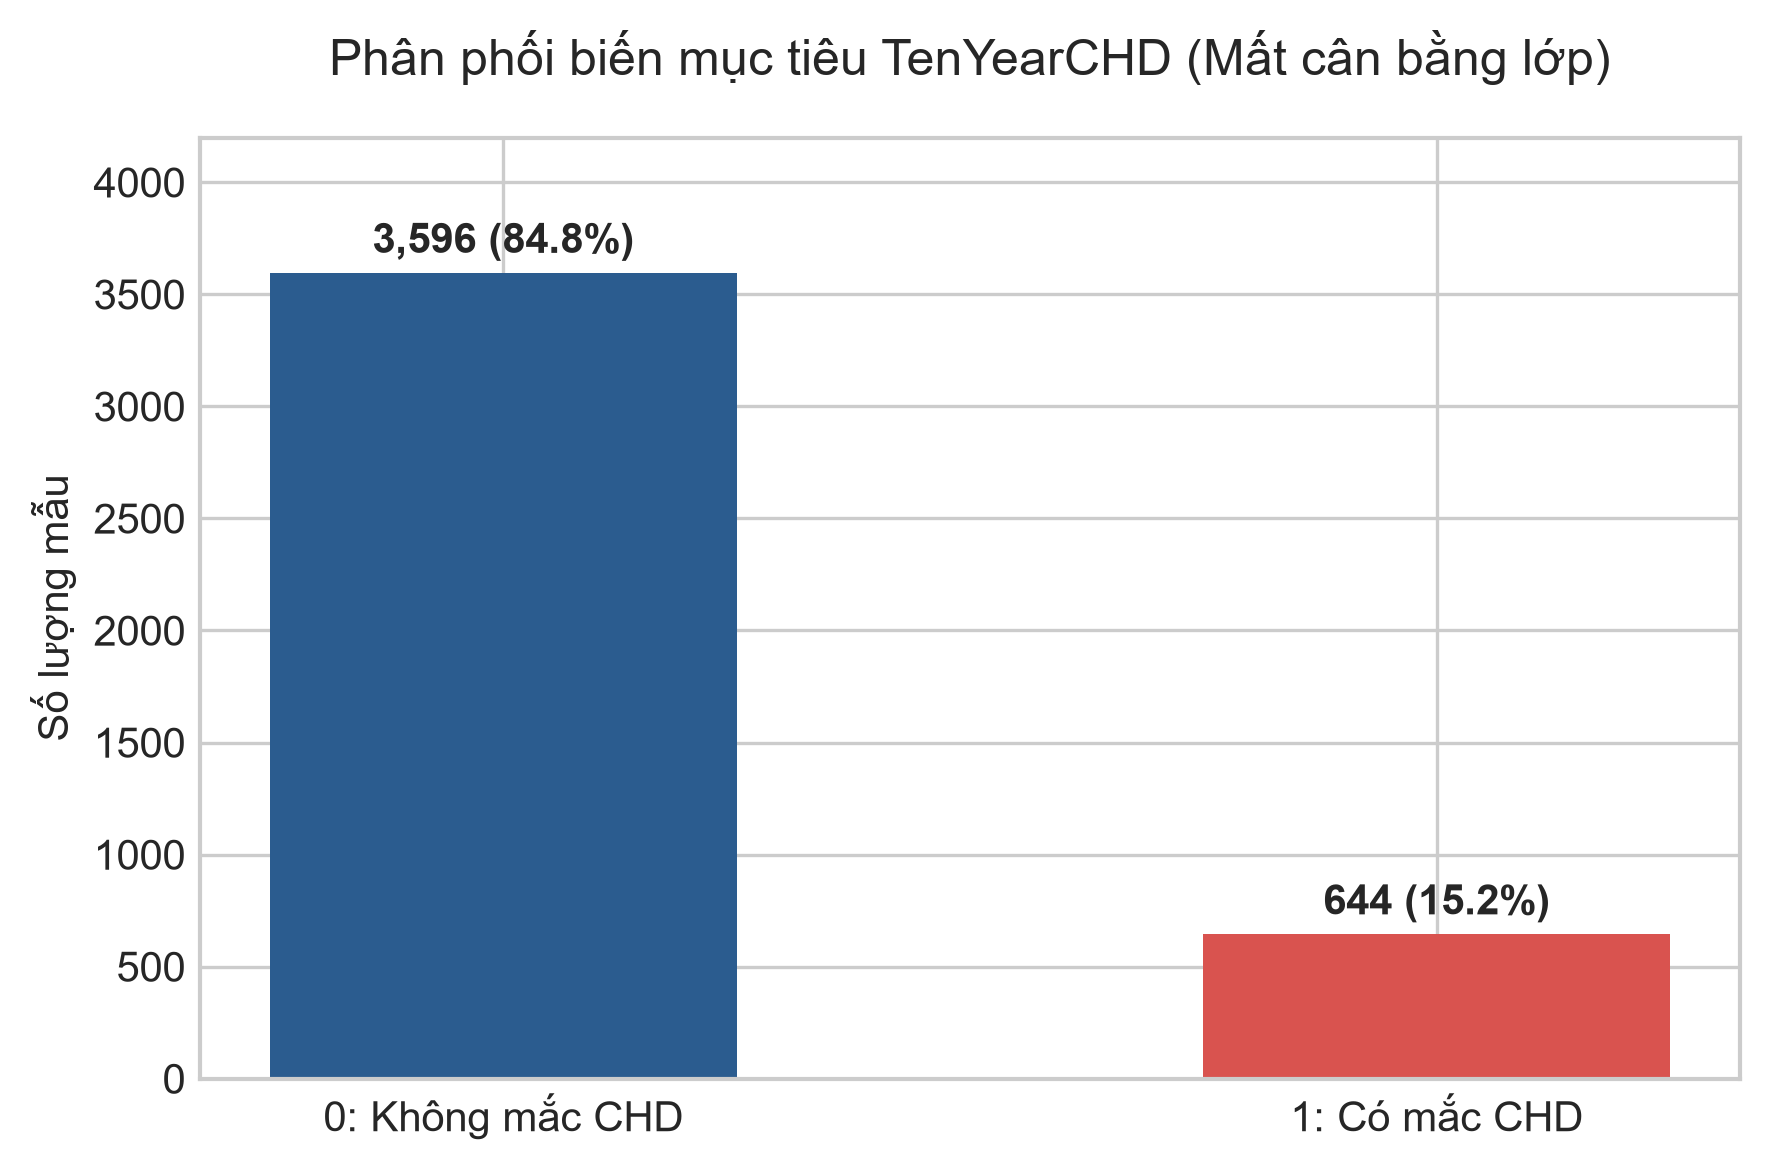

: 

: 

In [ ]:
# 3.1. Phân phối biến mục tiêu TenYearCHD (Mất cân bằng dữ liệu)
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)
counts = df[TARGET_COLUMN].value_counts()
colors = ['#2b5c8f', '#d9534f']
bars = ax.bar(['0: Không mắc CHD', '1: Có mắc CHD'], counts.values, color=colors, width=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 50, f'{yval:,} ({yval/len(df):.1%})', 
            ha='center', va='bottom', fontweight='bold')

ax.set_title('Phân phối biến mục tiêu TenYearCHD (Mất cân bằng lớp)', fontsize=12, pad=15)
ax.set_ylabel('Số lượng mẫu')
ax.set_ylim(0, 4200)
plt.tight_layout()
plt.show()

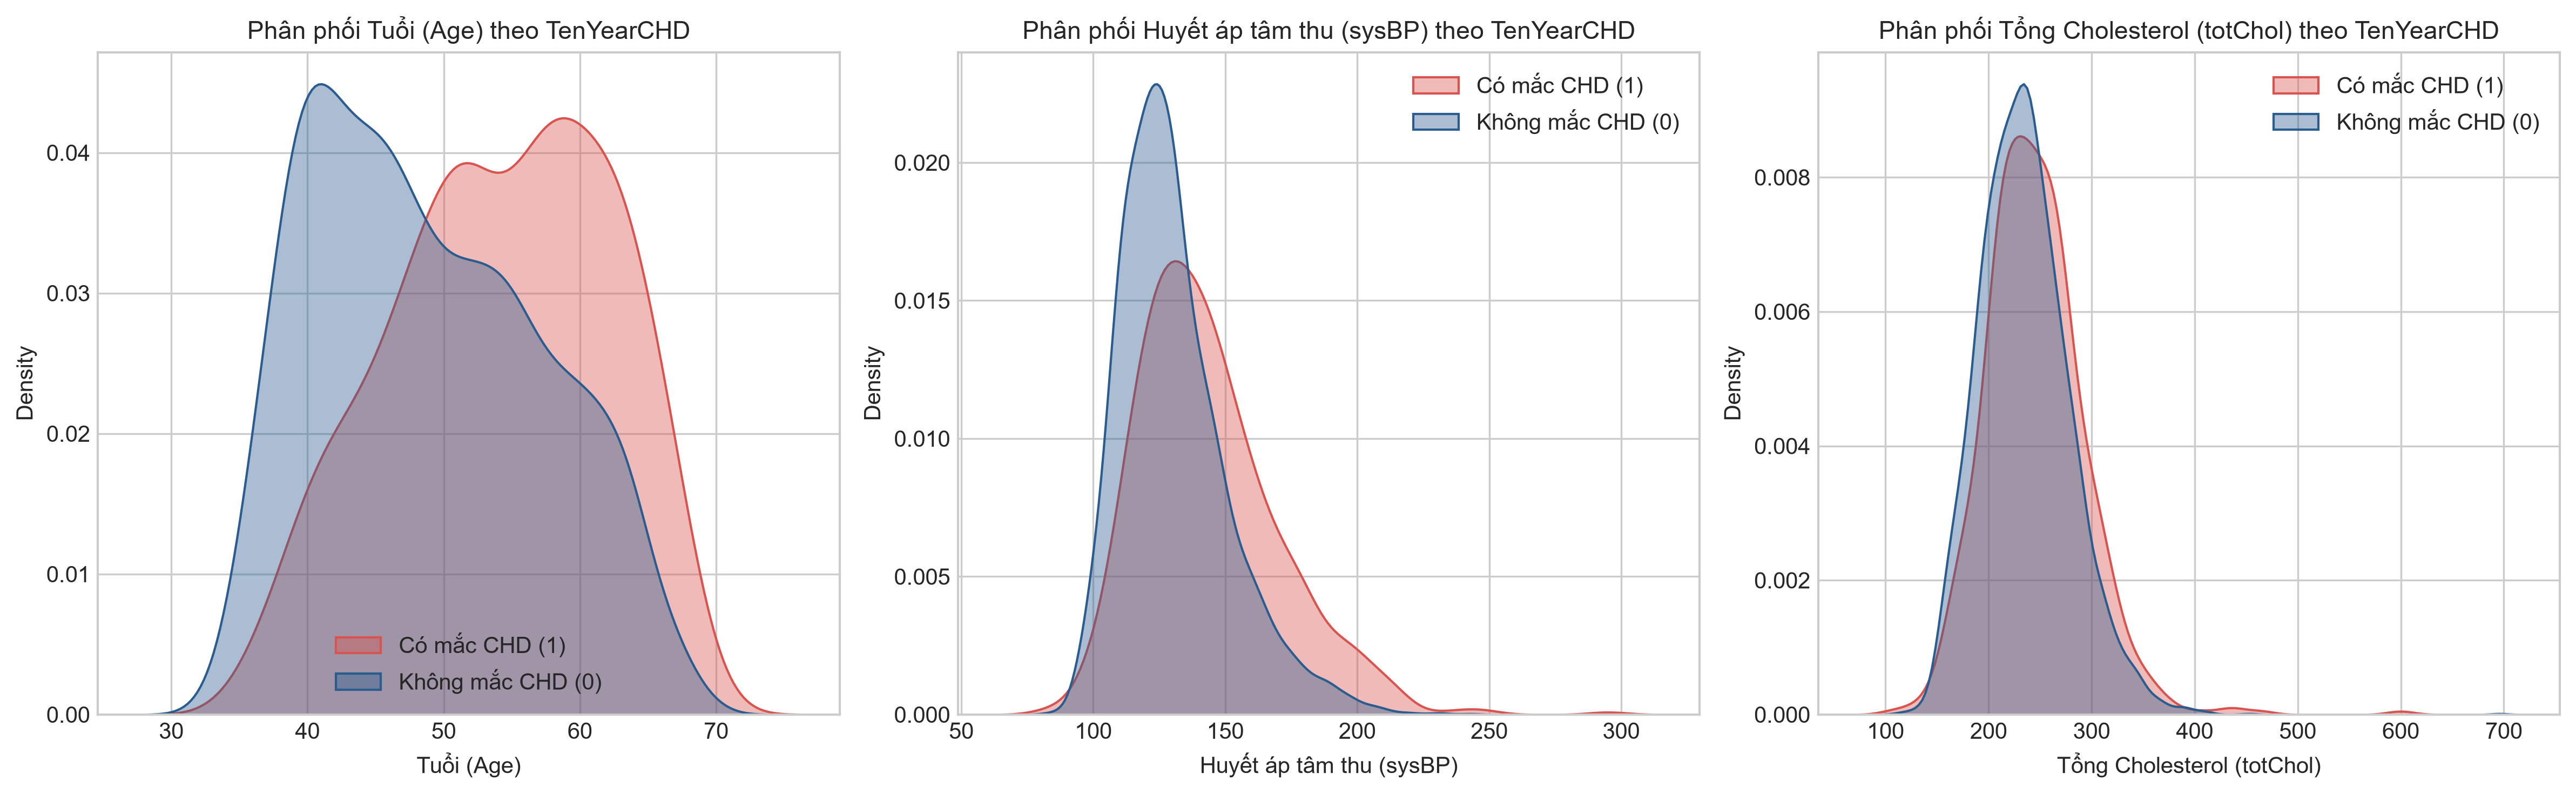

: 

: 

In [ ]:
# 3.2. Phân phối tuổi, huyết áp, cholesterol theo nhóm mắc bệnh
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300)
features_plot = [('age', 'Tuổi (Age)'), ('sysBP', 'Huyết áp tâm thu (sysBP)'), ('totChol', 'Tổng Cholesterol (totChol)')]

for i, (col, label) in enumerate(features_plot):
    sns.kdeplot(data=df, x=col, hue=TARGET_COLUMN, common_norm=False, 
                palette=['#2b5c8f', '#d9534f'], fill=True, alpha=0.4, ax=axes[i])
    axes[i].set_title(f'Phân phối {label} theo TenYearCHD', fontsize=11)
    axes[i].set_xlabel(label)
    axes[i].legend(['Có mắc CHD (1)', 'Không mắc CHD (0)'])

plt.tight_layout()
plt.show()

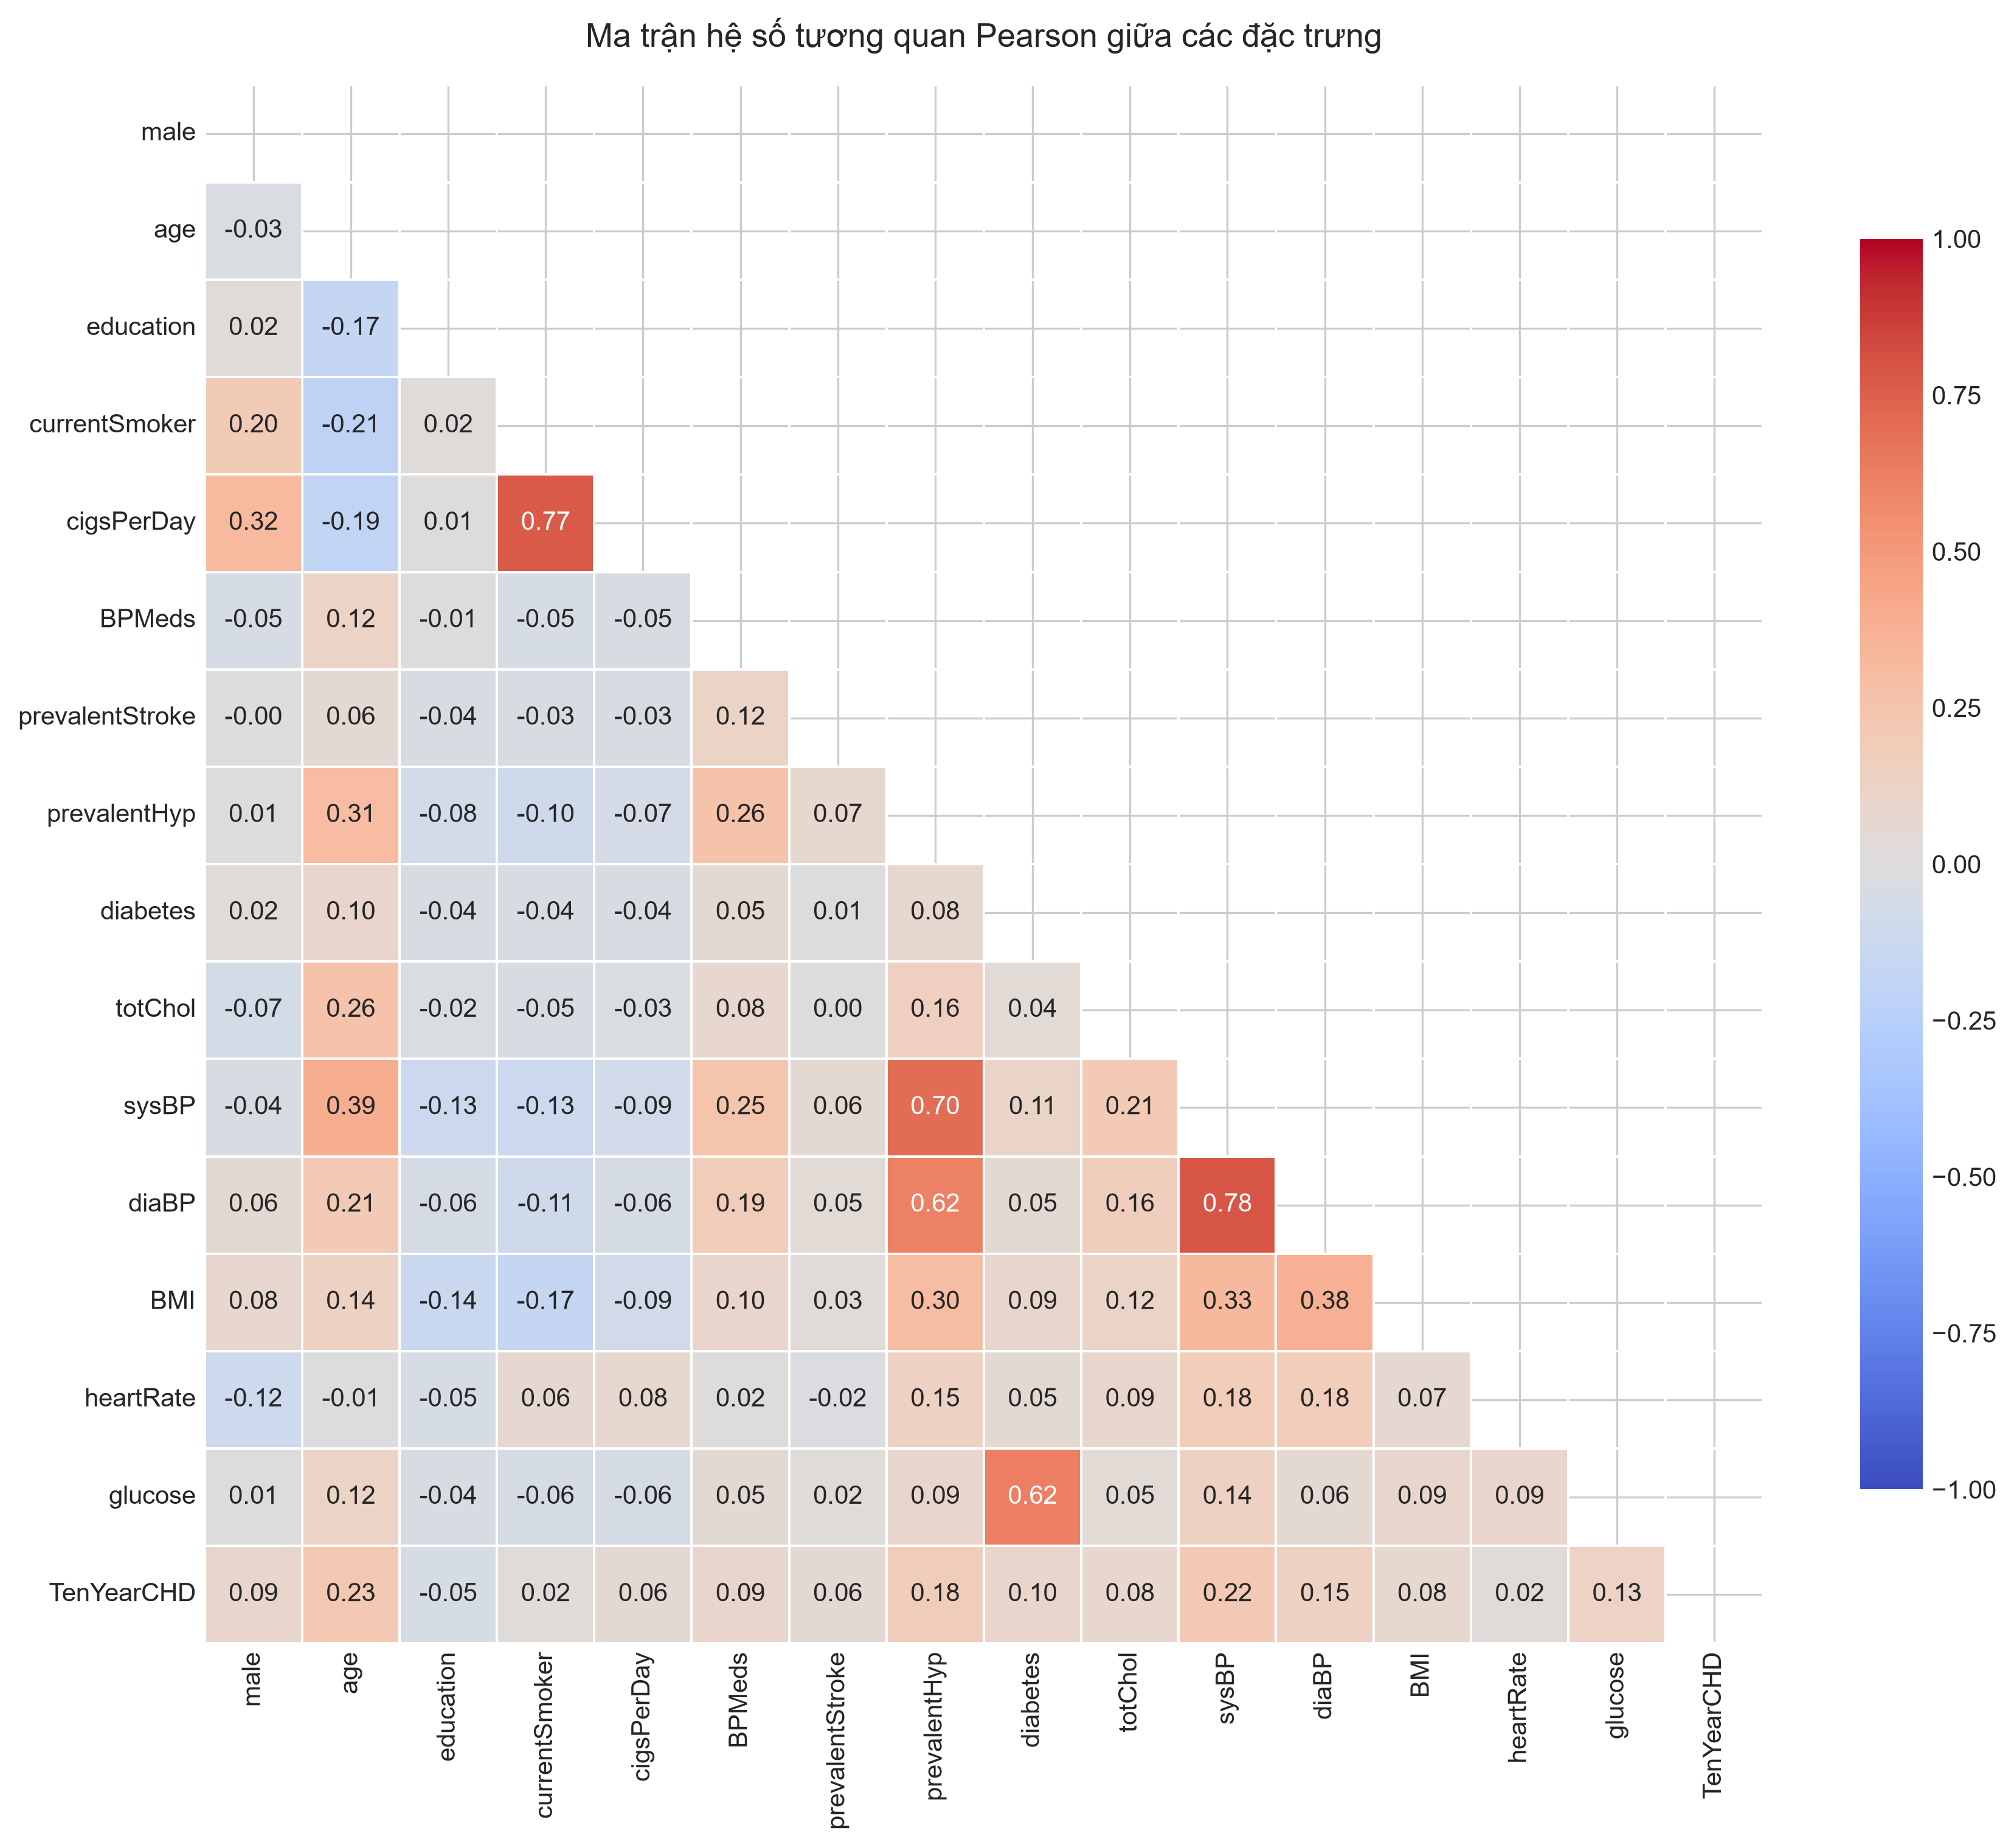

: 

: 

In [ ]:
# 3.3. Ma trận tương quan (Correlation Matrix Heatmap)
fig, ax = plt.subplots(figsize=(12, 10), dpi=300)
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, 
            center=0, square=True, linewidths=.5, cbar_kws={'shrink': .8}, ax=ax)
ax.set_title('Ma trận hệ số tương quan Pearson giữa các đặc trưng', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

> **Nhận xét quan trọng:**
> 1. **Tương quan mạnh giữa huyết áp tâm thu (`sysBP`) và tâm trương (`diaBP`)**: Hệ số tương quan $r = 0.78$. Cả hai phản ánh tình trạng áp lực lòng mạch. Do đó, việc kết hợp thành các chỉ số y khoa như **Áp lực mạch (Pulse Pressure)** và **Huyết áp trung bình (MAP)** là có cơ sở khoa học vững chắc.
> 2. **Tương quan giữa `currentSmoker` và `cigsPerDay`** ($r = 0.77$): Người hút thuốc có nguy cơ cao hơn khi tuổi tác tăng lên. Đặc trưng tích hợp `age_cigs_interaction` sẽ nắm bắt hiệu ứng tương tác này.

---
### 3.4 Bổ sung EDA biến số liên tục theo nhóm bệnh (TV3 - STT 3)
Các ô 3.1 - 3.3 phía trên đã vẽ phân phối `TenYearCHD` và KDE của `age`, `sysBP`, `totChol`. Phần bổ sung của **Thành viên 3** hoàn thiện yêu cầu STT 3:
- Thêm các biến còn thiếu (`diaBP`, `BMI`, `glucose`), boxplot, bảng thống kê + kiểm định Mann-Whitney U, tỷ lệ CHD theo nhóm tuổi.
- **Lưu toàn bộ ảnh `dpi=300`** vào `notebooks/figures/` để dán vào Báo cáo.

*Các biến của phần này đều có tiền tố `tv3_` để không ghi đè biến của thành viên khác.*

In [8]:
# 3.4.1 (TV3) Thống kê mô tả theo nhóm bệnh + kiểm định Mann-Whitney U (không giả định phân phối chuẩn)
from scipy.stats import mannwhitneyu

os.makedirs('../notebooks/figures', exist_ok=True)
tv3_cont_vars = {
    'age':     'Tuổi (năm)',
    'sysBP':   'Huyết áp tâm thu sysBP (mmHg)',
    'diaBP':   'Huyết áp tâm trương diaBP (mmHg)',
    'totChol': 'Tổng cholesterol (mg/dL)',
    'BMI':     'BMI (kg/m²)',
    'glucose': 'Đường huyết glucose (mg/dL)',
}
tv3_colors = {0: '#2b5c8f', 1: '#d9534f'}
tv3_labels = {0: 'Không mắc CHD (0)', 1: 'Có mắc CHD (1)'}

tv3_rows = []
for col in tv3_cont_vars:
    g0 = df.loc[df[TARGET_COLUMN] == 0, col].dropna()
    g1 = df.loc[df[TARGET_COLUMN] == 1, col].dropna()
    _, p = mannwhitneyu(g0, g1, alternative='two-sided')
    tv3_rows.append({'Biến': col,
                     'Mean (0)': g0.mean(), 'Mean (1)': g1.mean(),
                     'Median (0)': g0.median(), 'Median (1)': g1.median(),
                     'Chênh mean (1-0)': g1.mean() - g0.mean(), 'p-value': p})
tv3_stat_df = pd.DataFrame(tv3_rows).set_index('Biến')
tv3_stat_df.round(4)

,Mean (0),Mean (1),Median (0),Median (1),Chênh mean (1-0),p-value
Biến,,,,,,
age,48.7625,54.1460,48.00,55.000,5.3834,0.0000
sysBP,130.3373,143.6188,127.00,139.000,13.2815,0.0000
diaBP,82.1664,86.9814,81.00,85.500,4.8149,0.0000
totChol,235.1474,245.3890,232.00,241.000,10.2416,0.0000
BMI,25.6717,26.5315,25.25,26.155,0.8598,0.0000
glucose,80.6793,89.0084,78.00,79.000,8.3292,0.0007


Tỷ lệ mất cân bằng (lớp 0 : lớp 1) = 5.58 : 1


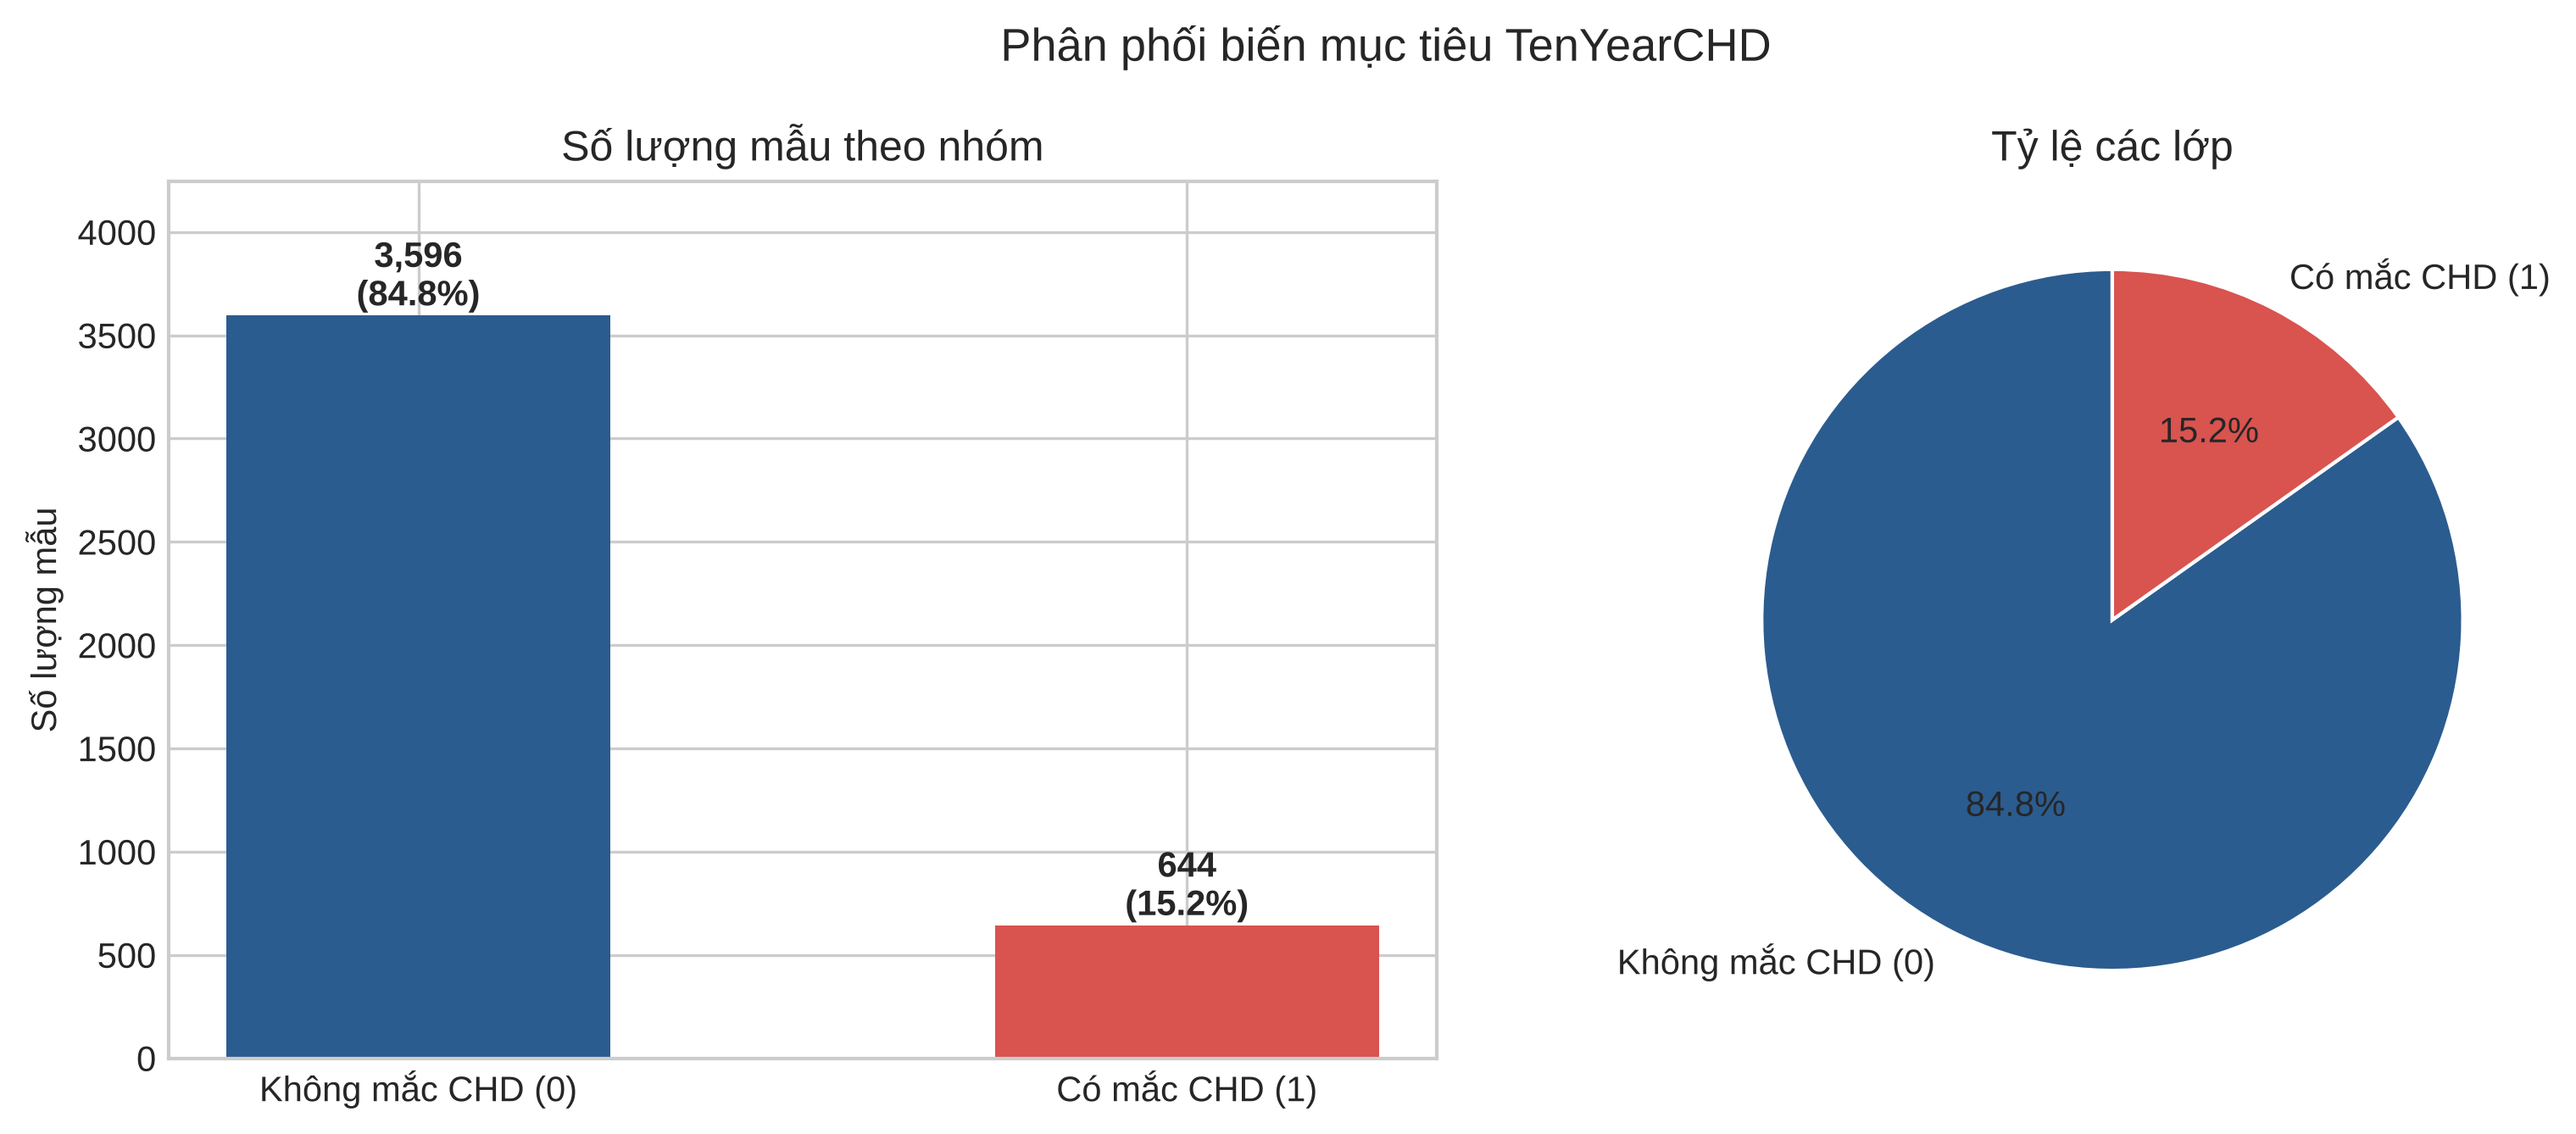

In [9]:
# 3.4.2 (TV3) Phân phối biến mục tiêu - bản lưu dpi=300 cho Báo cáo
tv3_counts = df[TARGET_COLUMN].value_counts().sort_index()
tv3_pct = tv3_counts / tv3_counts.sum() * 100
print(f'Tỷ lệ mất cân bằng (lớp 0 : lớp 1) = {tv3_counts[0] / tv3_counts[1]:.2f} : 1')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=300)
bars = axes[0].bar([tv3_labels[i] for i in tv3_counts.index], tv3_counts.values,
                   color=[tv3_colors[i] for i in tv3_counts.index], width=0.5)
for b, v, p in zip(bars, tv3_counts.values, tv3_pct.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v, f'{v:,}\n({p:.1f}%)', ha='center', va='bottom', fontweight='bold')
axes[0].set_ylim(0, tv3_counts.max() * 1.18)
axes[0].set_ylabel('Số lượng mẫu')
axes[0].set_title('Số lượng mẫu theo nhóm')
axes[1].pie(tv3_counts.values, labels=[tv3_labels[i] for i in tv3_counts.index], autopct='%1.1f%%',
            colors=[tv3_colors[i] for i in tv3_counts.index], startangle=90, wedgeprops={'edgecolor': 'white'})
axes[1].set_title('Tỷ lệ các lớp')
fig.suptitle('Phân phối biến mục tiêu TenYearCHD', fontsize=13)
plt.tight_layout()
fig.savefig('../notebooks/figures/eda_target_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

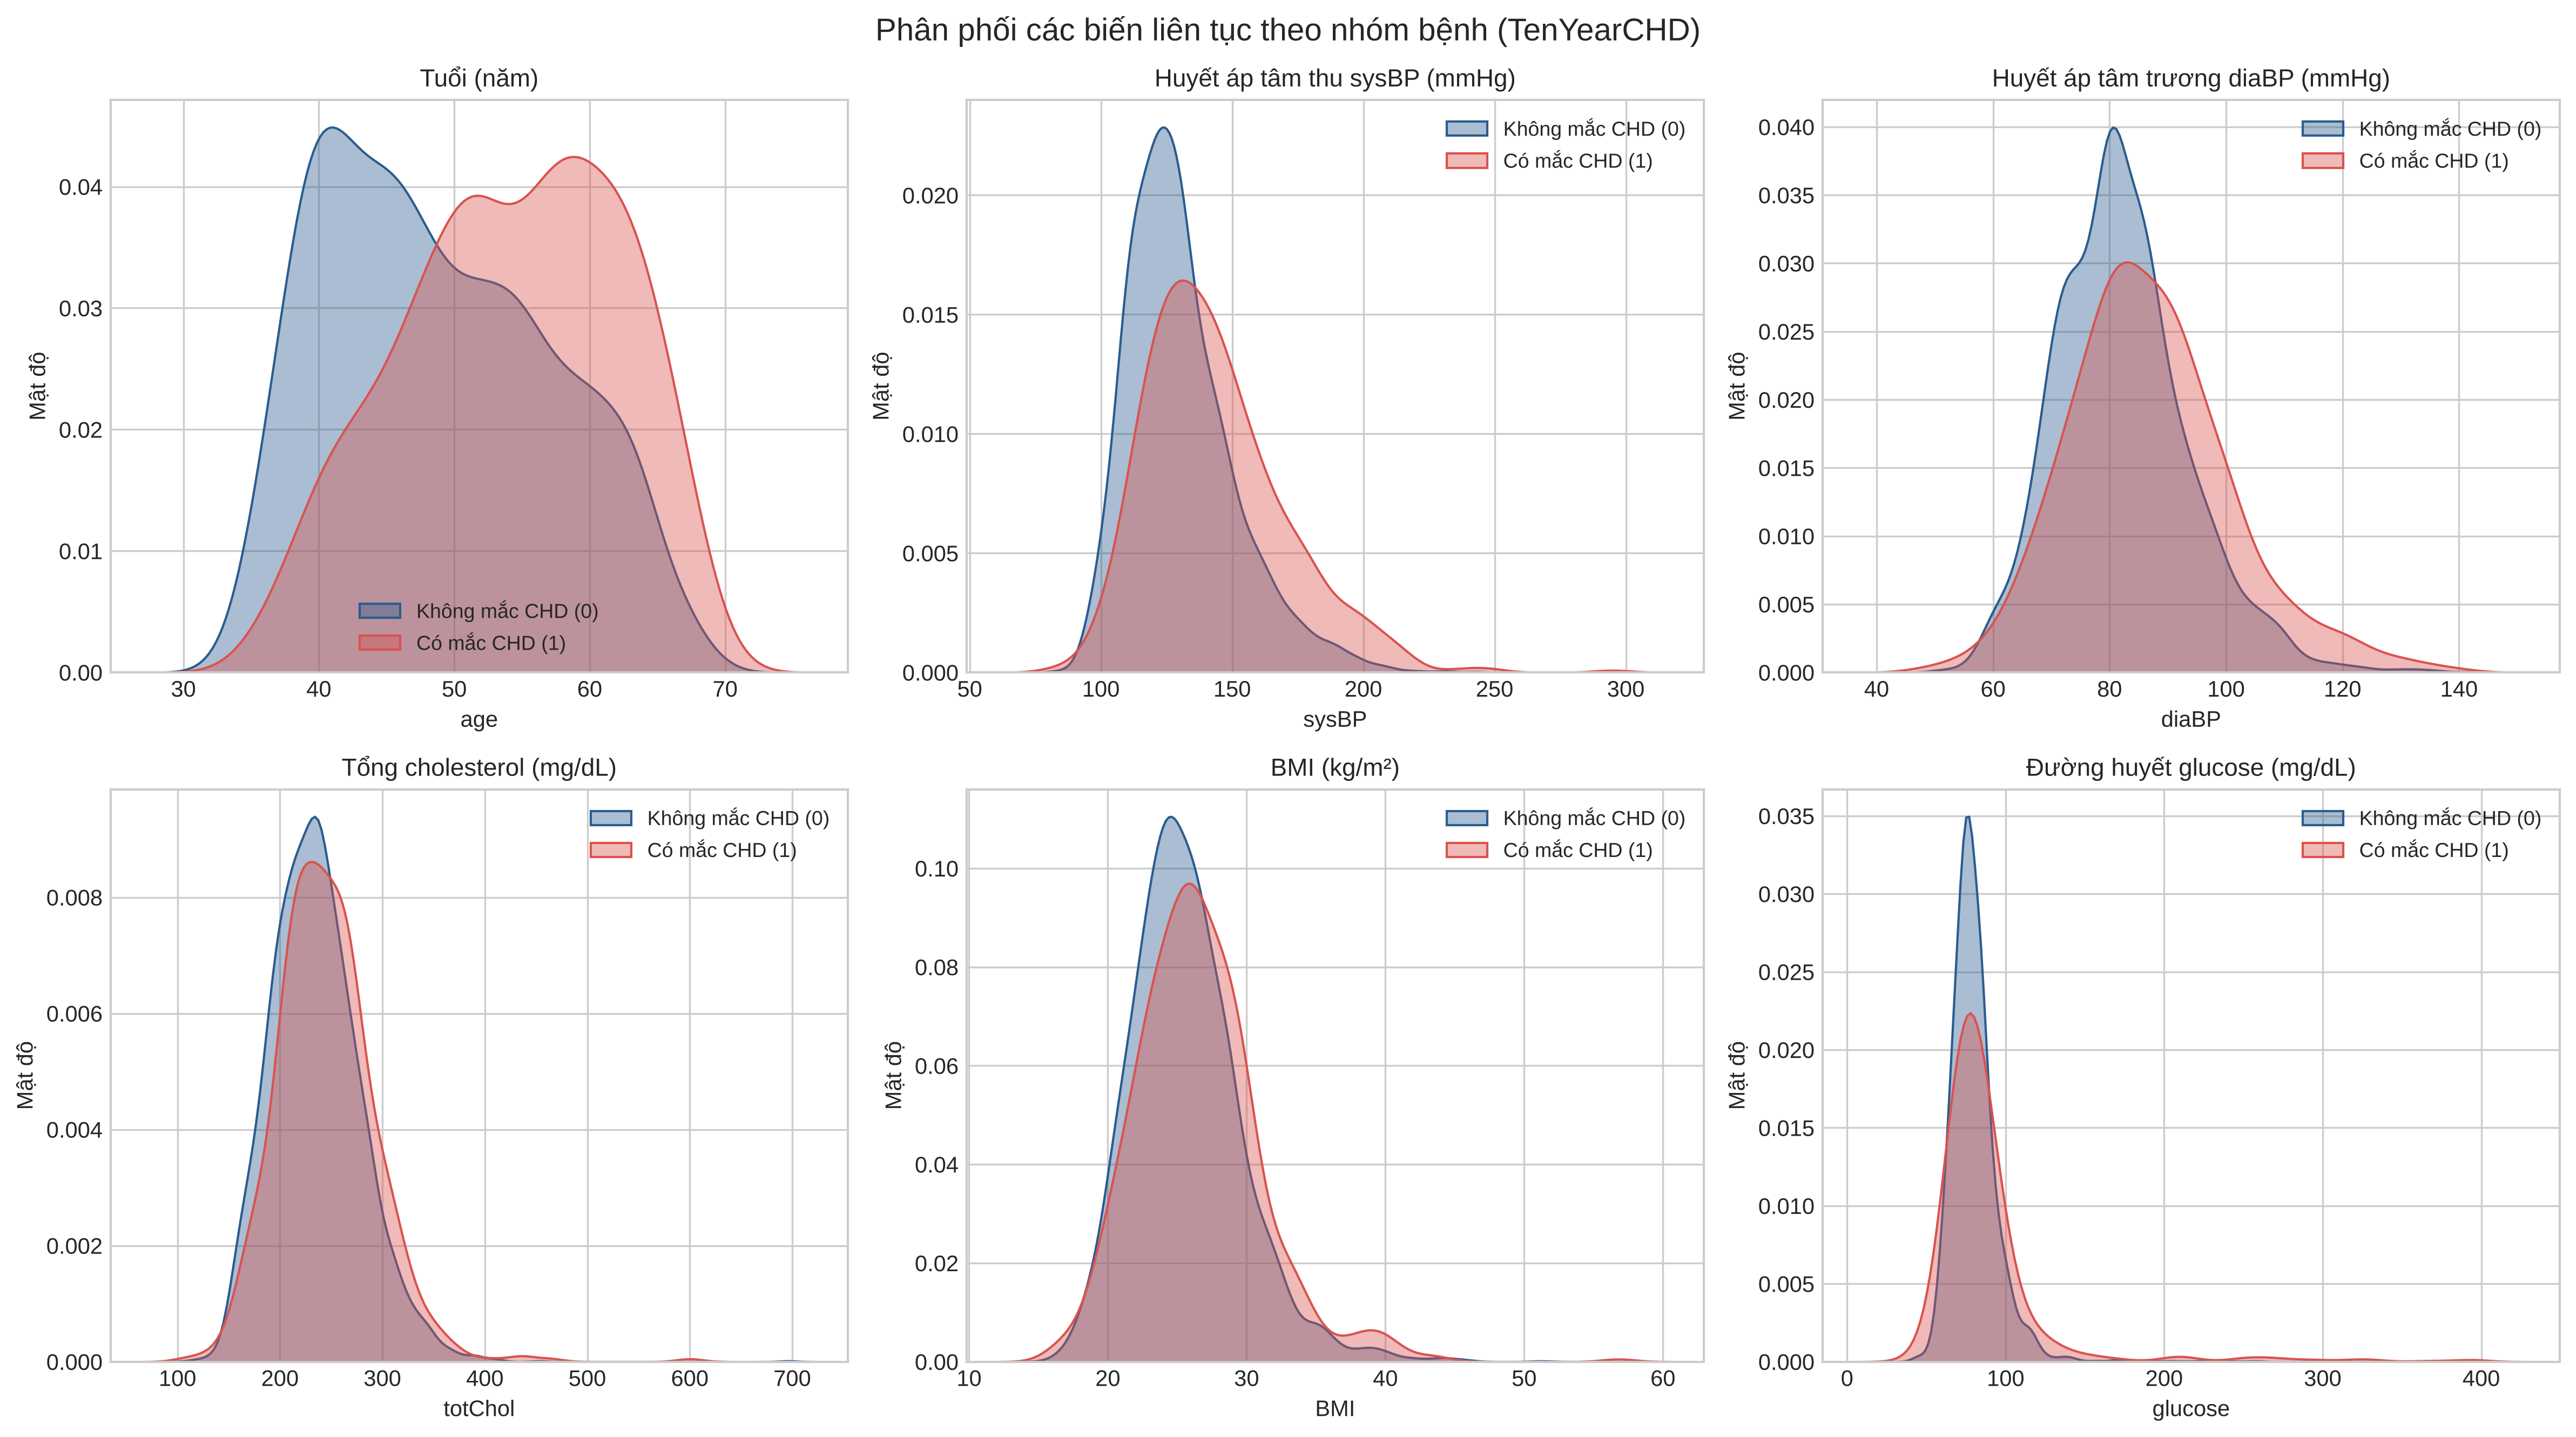

In [10]:
# 3.4.3 (TV3) Phân phối 6 biến liên tục theo nhóm bệnh (KDE) - lưu dpi=300
fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=300)
for ax, (col, name) in zip(axes.ravel(), tv3_cont_vars.items()):
    for k in (0, 1):
        sns.kdeplot(df.loc[df[TARGET_COLUMN] == k, col].dropna(), fill=True, alpha=0.4,
                    color=tv3_colors[k], label=tv3_labels[k], ax=ax)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel(col)
    ax.set_ylabel('Mật độ')
    ax.legend(fontsize=9)
fig.suptitle('Phân phối các biến liên tục theo nhóm bệnh (TenYearCHD)', fontsize=14)
plt.tight_layout()
fig.savefig('../notebooks/figures/eda_continuous_kde_by_target.png', dpi=300, bbox_inches='tight')
plt.show()

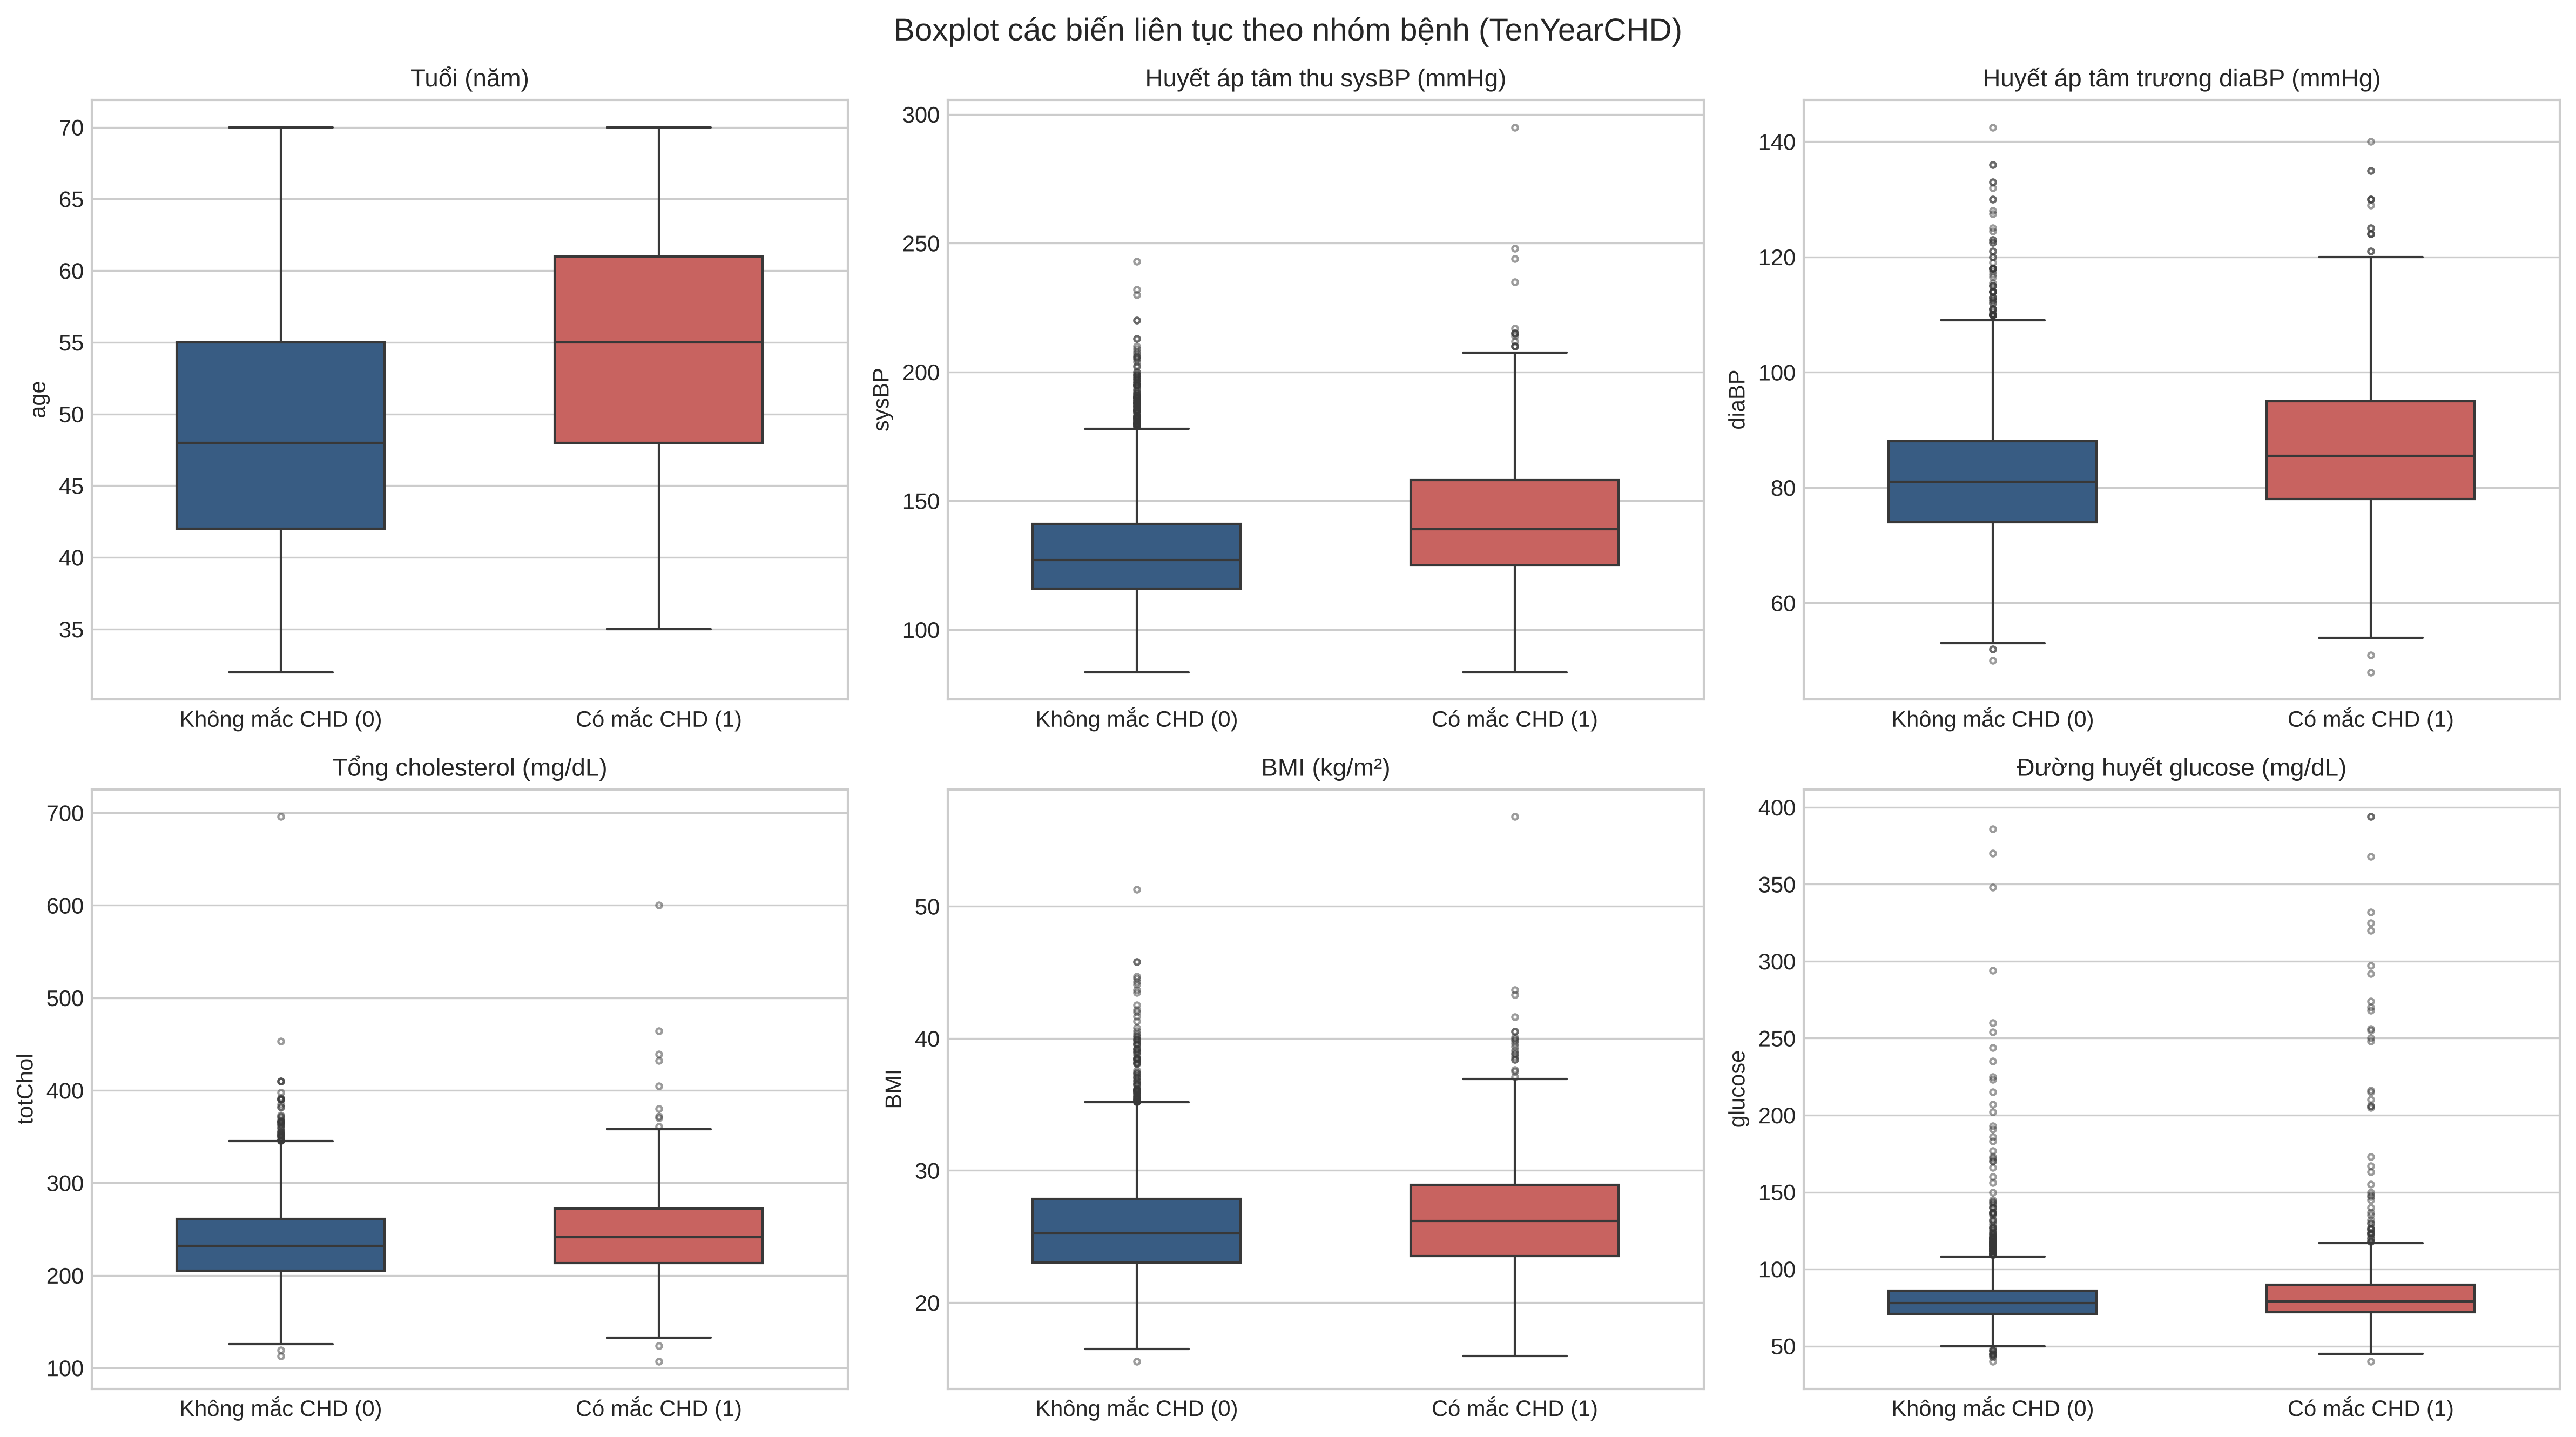

In [11]:
# 3.4.4 (TV3) Boxplot 6 biến liên tục theo nhóm bệnh - lưu dpi=300
fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=300)
for ax, (col, name) in zip(axes.ravel(), tv3_cont_vars.items()):
    sns.boxplot(data=df, x=TARGET_COLUMN, y=col, palette=[tv3_colors[0], tv3_colors[1]], ax=ax,
                width=0.55, flierprops={'markersize': 2.5, 'alpha': 0.5})
    ax.set_xticklabels([tv3_labels[0], tv3_labels[1]])
    ax.set_xlabel('')
    ax.set_ylabel(col)
    ax.set_title(name, fontsize=11)
fig.suptitle('Boxplot các biến liên tục theo nhóm bệnh (TenYearCHD)', fontsize=14)
plt.tight_layout()
fig.savefig('../notebooks/figures/eda_continuous_boxplot_by_target.png', dpi=300, bbox_inches='tight')
plt.show()

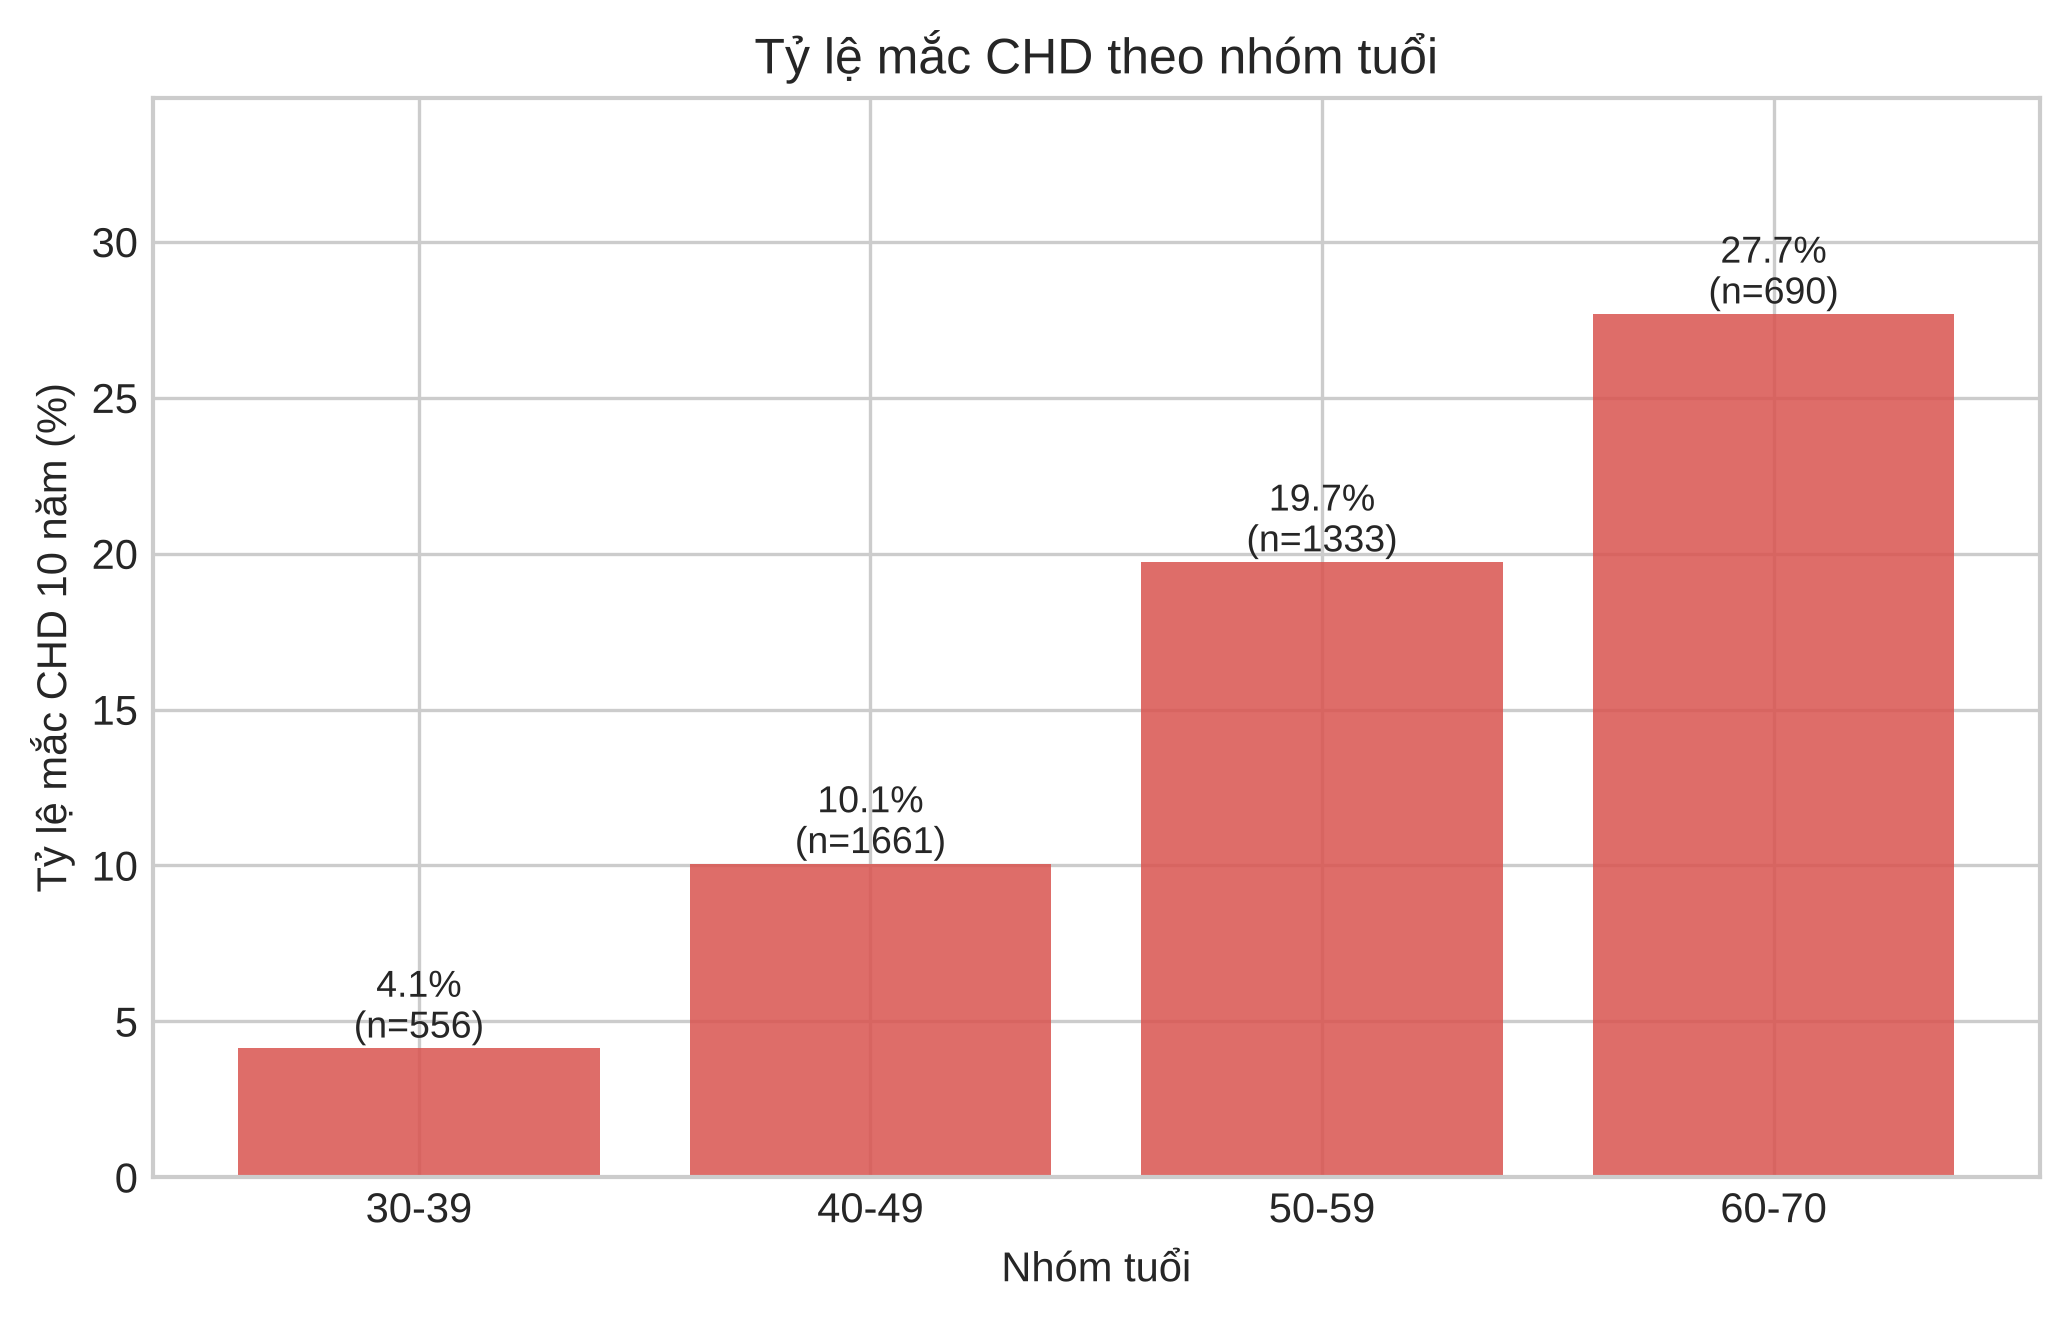

In [12]:
# 3.4.5 (TV3) Tỷ lệ mắc CHD theo nhóm tuổi - lưu dpi=300
tv3_age_grp = pd.cut(df['age'], bins=[30, 40, 50, 60, 71], right=False, labels=['30-39', '40-49', '50-59', '60-70'])
tv3_rate = df.groupby(tv3_age_grp, observed=True)[TARGET_COLUMN].agg(['mean', 'count'])

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)
bars = ax.bar(tv3_rate.index.astype(str), tv3_rate['mean'] * 100, color='#d9534f', alpha=0.85)
for b, (m, n) in zip(bars, tv3_rate[['mean', 'count']].values):
    ax.text(b.get_x() + b.get_width() / 2, m * 100, f'{m*100:.1f}%\n(n={int(n)})', ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, tv3_rate['mean'].max() * 100 * 1.25)
ax.set_xlabel('Nhóm tuổi')
ax.set_ylabel('Tỷ lệ mắc CHD 10 năm (%)')
ax.set_title('Tỷ lệ mắc CHD theo nhóm tuổi')
plt.tight_layout()
fig.savefig('../notebooks/figures/eda_chd_rate_by_age.png', dpi=300, bbox_inches='tight')
plt.show()

> **Nhận xét EDA biến số (TV3) - đối chiếu bảng 3.4.1 và các biểu đồ trên:**
> 1. **Tuổi** và **huyết áp (`sysBP`, `diaBP`)** tách hai nhóm rõ nhất: nhóm mắc CHD có phân phối dịch sang phải, trung vị cao hơn; tỷ lệ mắc CHD tăng đều theo nhóm tuổi.
> 2. **`totChol`** chênh lệch vừa phải. **`BMI`** chênh lệch nhỏ -> khả năng phân biệt riêng lẻ yếu.
> 3. **`glucose`**: median hai nhóm gần như bằng nhau, chênh lệch mean chủ yếu do đuôi phải rất dài (đường huyết cao / tiểu đường) -> nhiều ngoại lai, cần chuẩn hóa ổn định ở Pipeline.
> 4. Hai nhóm **chồng lấn nhiều** trên mọi biến, không có biến đơn lẻ nào tách hẳn hai lớp -> cần kết hợp nhiều đặc trưng và dùng ROC-AUC / Recall / F1 thay vì chỉ Accuracy (dữ liệu mất cân bằng).
> 5. *(Ngoại lai chi tiết và các biến phân loại: phần của TV4.)*

---
## 4. Kỹ Thuật Tạo Đặc Trưng Mới (Feature Engineering - STT 5)
Dựa trên kiến thức chuyên môn tim mạch và phân tích EDA ở trên, ta tạo 3 đặc trưng mới:
1. **`pulse_pressure` (Áp lực mạch):**
   $$\text{pulse\_pressure} = \text{sysBP} - \text{diaBP}$$
   *Ý nghĩa y học:* Độ chênh lệch phản ánh độ cứng thành động mạch. Áp lực mạch cao (> 60 mmHg) là yếu tố độc lập dự báo xơ vữa động mạch và đột quỵ.
2. **`MAP` (Mean Arterial Pressure - Huyết áp động mạch trung bình):**
   $$\text{MAP} = \text{diaBP} + \frac{\text{sysBP} - \text{diaBP}}{3}$$
   *Ý nghĩa y học:* Áp lực tưới máu thực tế liên tục đến các cơ quan quan trọng, toàn diện hơn huyết áp đơn lẻ.
3. **`age_cigs_interaction` (Tương tác Tuổi x Lượng thuốc lá):**
   $$\text{age\_cigs\_interaction} = \text{age} \times \text{cigsPerDay}$$
   *Ý nghĩa y học:* Mức độ phơi nhiễm độc chất khói thuốc theo thời gian tích lũy theo số năm tuổi.

In [ ]:
# Thử nghiệm hàm create_features từ module src/features.py
df_featured = create_features(df)
print('3 đặc trưng mới đã được bổ sung vào DataFrame:')
df_featured[['sysBP', 'diaBP', 'pulse_pressure', 'MAP', 'age', 'cigsPerDay', 'age_cigs_interaction']].head()

3 đặc trưng mới đã được bổ sung vào DataFrame:


,sysBP,diaBP,pulse_pressure,MAP,age,cigsPerDay,age_cigs_interaction
0,106.0,70.0,36.0,82.000000,39,0.0,0.0
1,121.0,81.0,40.0,94.333333,46,0.0,0.0
2,127.5,80.0,47.5,95.833333,48,20.0,960.0
3,150.0,95.0,55.0,113.333333,61,30.0,1830.0
4,130.0,84.0,46.0,99.333333,46,23.0,1058.0


: 

: 

---
## 5. Chia Tập Dữ Liệu Train / Test (Tuân Thủ Tuyệt Đối Quy Ước 1 & 2)
> ⚠️ **LƯU Ý BẮT BUỘC ĐỂ KHÔNG BỊ TRỪ ĐIỂM (Data Leakage):**
> - BẮT BUỘC thực hiện chia tập Train (80%) và Test (20%) bằng `train_test_split` trước khi thực hiện bất kỳ phép `fit` nào của Imputer hoặc Scaler.
> - Dùng `stratify=y` và `random_state=42` để cố định dữ liệu và bảo toàn tỷ lệ nhãn cho cả 3 máy.

In [ ]:
# Gọi hàm load_and_split_data chuẩn từ module src/features.py
X_train, X_test, y_train, y_test = load_and_split_data(
    data_path='../data/framingham.csv',
    test_size=0.2,
    random_state=42
)

print(f'Kích thước X_train: {X_train.shape} | y_train: {y_train.shape}')
print(f'Kích thước X_test:  {X_test.shape}  | y_test:  {y_test.shape}')
print(f'Tỷ lệ nhãn dương (TenYearCHD=1) trên Train: {y_train.mean():.4f}')
print(f'Tỷ lệ nhãn dương (TenYearCHD=1) trên Test:  {y_test.mean():.4f}')

Kích thước X_train: (3392, 15) | y_train: (3392,)
Kích thước X_test:  (848, 15)  | y_test:  (848,)
Tỷ lệ nhãn dương (TenYearCHD=1) trên Train: 0.1518
Tỷ lệ nhãn dương (TenYearCHD=1) trên Test:  0.1521


: 

: 

---
## 6. Đóng Gói Bộ Tiền Xử Lý Pipeline (ColumnTransformer) Chống Rò Rỉ Dữ Liệu
Toàn bộ quy trình tiền xử lý được đóng gói trong một `Pipeline` duy nhất gồm:
1. **`HeartDiseaseFeatureEngineer`:** Tự động tính toán 3 đặc trưng mới trên dữ liệu.
2. **`ColumnTransformer`:**
   - **11 Đặc trưng số:** `SimpleImputer(strategy='median')` -> `StandardScaler()`
   - **7 Đặc trưng phân loại:** `SimpleImputer(strategy='most_frequent')`

**Cơ chế chống Data Leakage:**
- `pipeline.fit(X_train)`: Chỉ học Median và Mean/Std từ `X_train`.
- `pipeline.transform(X_test)`: Dùng nguyên các thông số học được từ `X_train` áp dụng lên `X_test`.

In [ ]:
# Khởi tạo Pipeline tiền xử lý hoàn chỉnh từ src/features.py
preprocessor_pipeline = get_preprocessor_pipeline()
print('Pipeline đã khởi tạo thành công:')
preprocessor_pipeline

Pipeline đã khởi tạo thành công:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, def

: 

: 

In [ ]:
# FIT CHỈ TRÊN TẬP TRAIN (Chống rò rỉ dữ liệu)
preprocessor_pipeline.fit(X_train, y_train)

# Transform trên cả Train và Test độc lập
X_train_processed = preprocessor_pipeline.transform(X_train)
X_test_processed = preprocessor_pipeline.transform(X_test)

print(f'X_train sau tiền xử lý: {X_train_processed.shape}')
print(f'X_test sau tiền xử lý:  {X_test_processed.shape}')
print(f'Số giá trị NaN còn lại trong X_train: {np.isnan(X_train_processed).sum()}')
print(f'Số giá trị NaN còn lại trong X_test:  {np.isnan(X_test_processed).sum()}')

X_train sau tiền xử lý: (3392, 18)
X_test sau tiền xử lý:  (848, 18)
Số giá trị NaN còn lại trong X_train: 0
Số giá trị NaN còn lại trong X_test:  0


: 

: 

## 7. Xuất & Lưu Pipeline Hoàn Chỉnh Cho Thành Viên 2 (Phụ Trách Mô Hình)
Lưu `preprocessor_pipeline` đã fit vào thư mục `models/` để Thành viên 2 (Mô hình Baseline & Multi-Model) lắp trực tiếp vào mô hình huấn luyện.

In [ ]:
import joblib

os.makedirs('../models', exist_ok=True)
pipeline_save_path = '../models/preprocessor_pipeline.joblib'
joblib.dump(preprocessor_pipeline, pipeline_save_path)
print(f'Đã lưu thành công bộ tiền xử lý Pipeline tại: {pipeline_save_path}')
print('Hoàn tất toàn bộ yêu cầu của STT 5 (Mốc 1 Checkpoint 1)!')

Đã lưu thành công bộ tiền xử lý Pipeline tại: ../models/preprocessor_pipeline.joblib
Hoàn tất toàn bộ yêu cầu của STT 5 (Mốc 1 Checkpoint 1)!


: 

: 

---
# ĐỐI CHIẾU SƠ BỘ: DECISION TREE & k-NN (TV3 - STT 7)
**Thành viên phụ trách:** Thành viên 3 | **Mốc chấm:** Milestone 1 (Checkpoint Buổi 4)

Mục tiêu: chạy thử sớm Decision Tree và k-NN cơ bản trên **Pipeline của TV1**, đối chiếu với Baseline Logistic Regression của TV2.
- Cùng split (`X_train`, `X_test` của TV1), cùng `StratifiedKFold(5, shuffle=True, random_state=42)`, cùng bộ metric.
- Tiền xử lý nằm **trong** Pipeline nên mỗi fold tự fit trên phần train -> không rò rỉ dữ liệu.
- File này chạy **độc lập** (chưa có phần TV2), nên hàng Logistic Regression được tính lại với **đúng cấu hình của TV2** (`class_weight='balanced'`, `max_iter=1000`, `random_state=42`) chỉ để làm mốc. Kết quả chính thức của Baseline lấy từ phần TV2.
- Chưa tuning siêu tham số (thuộc Milestone 2). Decision Tree giới hạn `max_depth=5` để tránh overfit quá nặng.

In [18]:
# 1. (TV3) Pipeline Logistic Regression (mốc) / Decision Tree / k-NN trên tiền xử lý của TV1 + Stratified 5-Fold CV
import time
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (roc_auc_score, recall_score, f1_score, precision_score,
                             accuracy_score, confusion_matrix, roc_curve)

tv3_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tv3_scoring = ['roc_auc', 'recall', 'f1', 'precision', 'accuracy']

tv3_models = {
    'Logistic Regression (mốc TV2)': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Decision Tree (max_depth=5)':   DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'k-NN (k=5)':                    KNeighborsClassifier(n_neighbors=5),
}

tv3_cv_res, tv3_pred = {}, {}
for name, clf in tv3_models.items():
    t0 = time.time()
    pipe = Pipeline([('preprocessor', get_preprocessor_pipeline()), ('classifier', clf)])
    tv3_cv_res[name] = cross_validate(pipe, X_train, y_train, cv=tv3_cv, scoring=tv3_scoring, n_jobs=-1)
    pipe.fit(X_train, y_train)                      # fit trên toàn bộ X_train
    tv3_pred[name] = {
        'y_pred': pipe.predict(X_test),
        'y_prob': pipe.predict_proba(X_test)[:, 1],
        'train_auc': roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1]),
    }
    print(f'{name}: xong ({time.time() - t0:.1f}s)')
tv3_order = list(tv3_models.keys())

Logistic Regression (mốc TV2): xong (0.3s)


Decision Tree (max_depth=5): xong (0.3s)


k-NN (k=5): xong (0.4s)


In [19]:
# 2. (TV3) Bảng đối chiếu: Cross-Validation (Train) và Test holdout
tv3_cv_rows, tv3_test_rows = [], []
for name in tv3_order:
    r = tv3_cv_res[name]
    row = {'Mô hình': name}
    for m, lab in [('roc_auc', 'ROC-AUC'), ('recall', 'Recall'), ('f1', 'F1'),
                   ('precision', 'Precision'), ('accuracy', 'Accuracy')]:
        row[f'CV {lab}'] = f"{r[f'test_{m}'].mean():.4f} ± {r[f'test_{m}'].std():.4f}"
    tv3_cv_rows.append(row)

    p = tv3_pred[name]
    test_auc = roc_auc_score(y_test, p['y_prob'])
    tv3_test_rows.append({
        'Mô hình': name,
        'ROC-AUC': test_auc,
        'Recall': recall_score(y_test, p['y_pred']),
        'F1': f1_score(y_test, p['y_pred']),
        'Precision': precision_score(y_test, p['y_pred'], zero_division=0),
        'Accuracy': accuracy_score(y_test, p['y_pred']),
        'Train ROC-AUC': p['train_auc'],
        'Gap (Train - Test AUC)': p['train_auc'] - test_auc,
    })

tv3_cv_df = pd.DataFrame(tv3_cv_rows).set_index('Mô hình')
tv3_test_df = pd.DataFrame(tv3_test_rows).set_index('Mô hình')
print('=== Stratified 5-Fold CV trên tập Train (Mean ± Std) ===')
print(tv3_cv_df.to_string())
print('\n=== Test holdout + mức overfit ===')
print(tv3_test_df.round(4).to_string())

=== Stratified 5-Fold CV trên tập Train (Mean ± Std) ===
                                    CV ROC-AUC        CV Recall            CV F1     CV Precision      CV Accuracy
Mô hình                                                                                                           
Logistic Regression (mốc TV2)  0.7307 ± 0.0302  0.6816 ± 0.0390  0.3893 ± 0.0320  0.2728 ± 0.0264  0.6740 ± 0.0288
Decision Tree (max_depth=5)    0.6625 ± 0.0430  0.6194 ± 0.0989  0.3363 ± 0.0410  0.2314 ± 0.0259  0.6309 ± 0.0279
k-NN (k=5)                     0.6195 ± 0.0213  0.0893 ± 0.0225  0.1405 ± 0.0281  0.3573 ± 0.0718  0.8358 ± 0.0084

=== Test holdout + mức overfit ===
                               ROC-AUC  Recall      F1  Precision  Accuracy  Train ROC-AUC  Gap (Train - Test AUC)
Mô hình                                                                                                           
Logistic Regression (mốc TV2)   0.7002  0.5969  0.3557     0.2533    0.6710         0.7410            

Đã lưu: ../models/results/early_comparison_tv3.csv


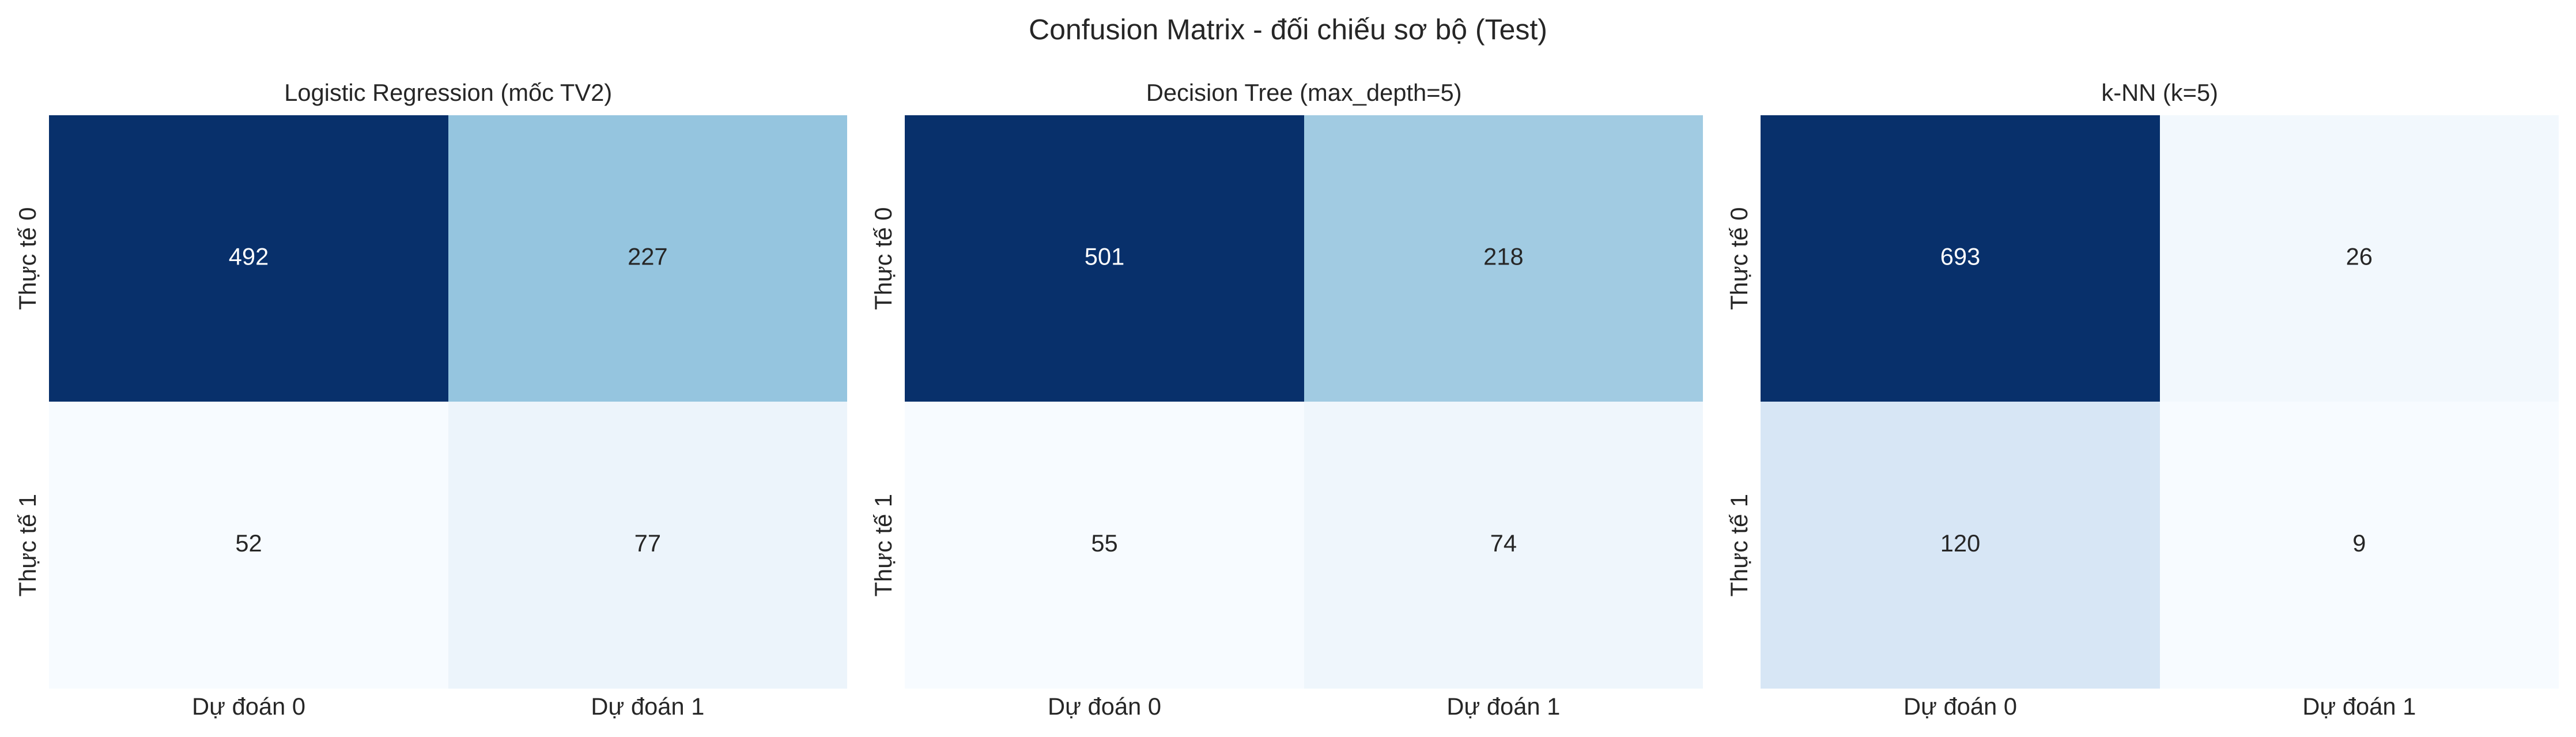

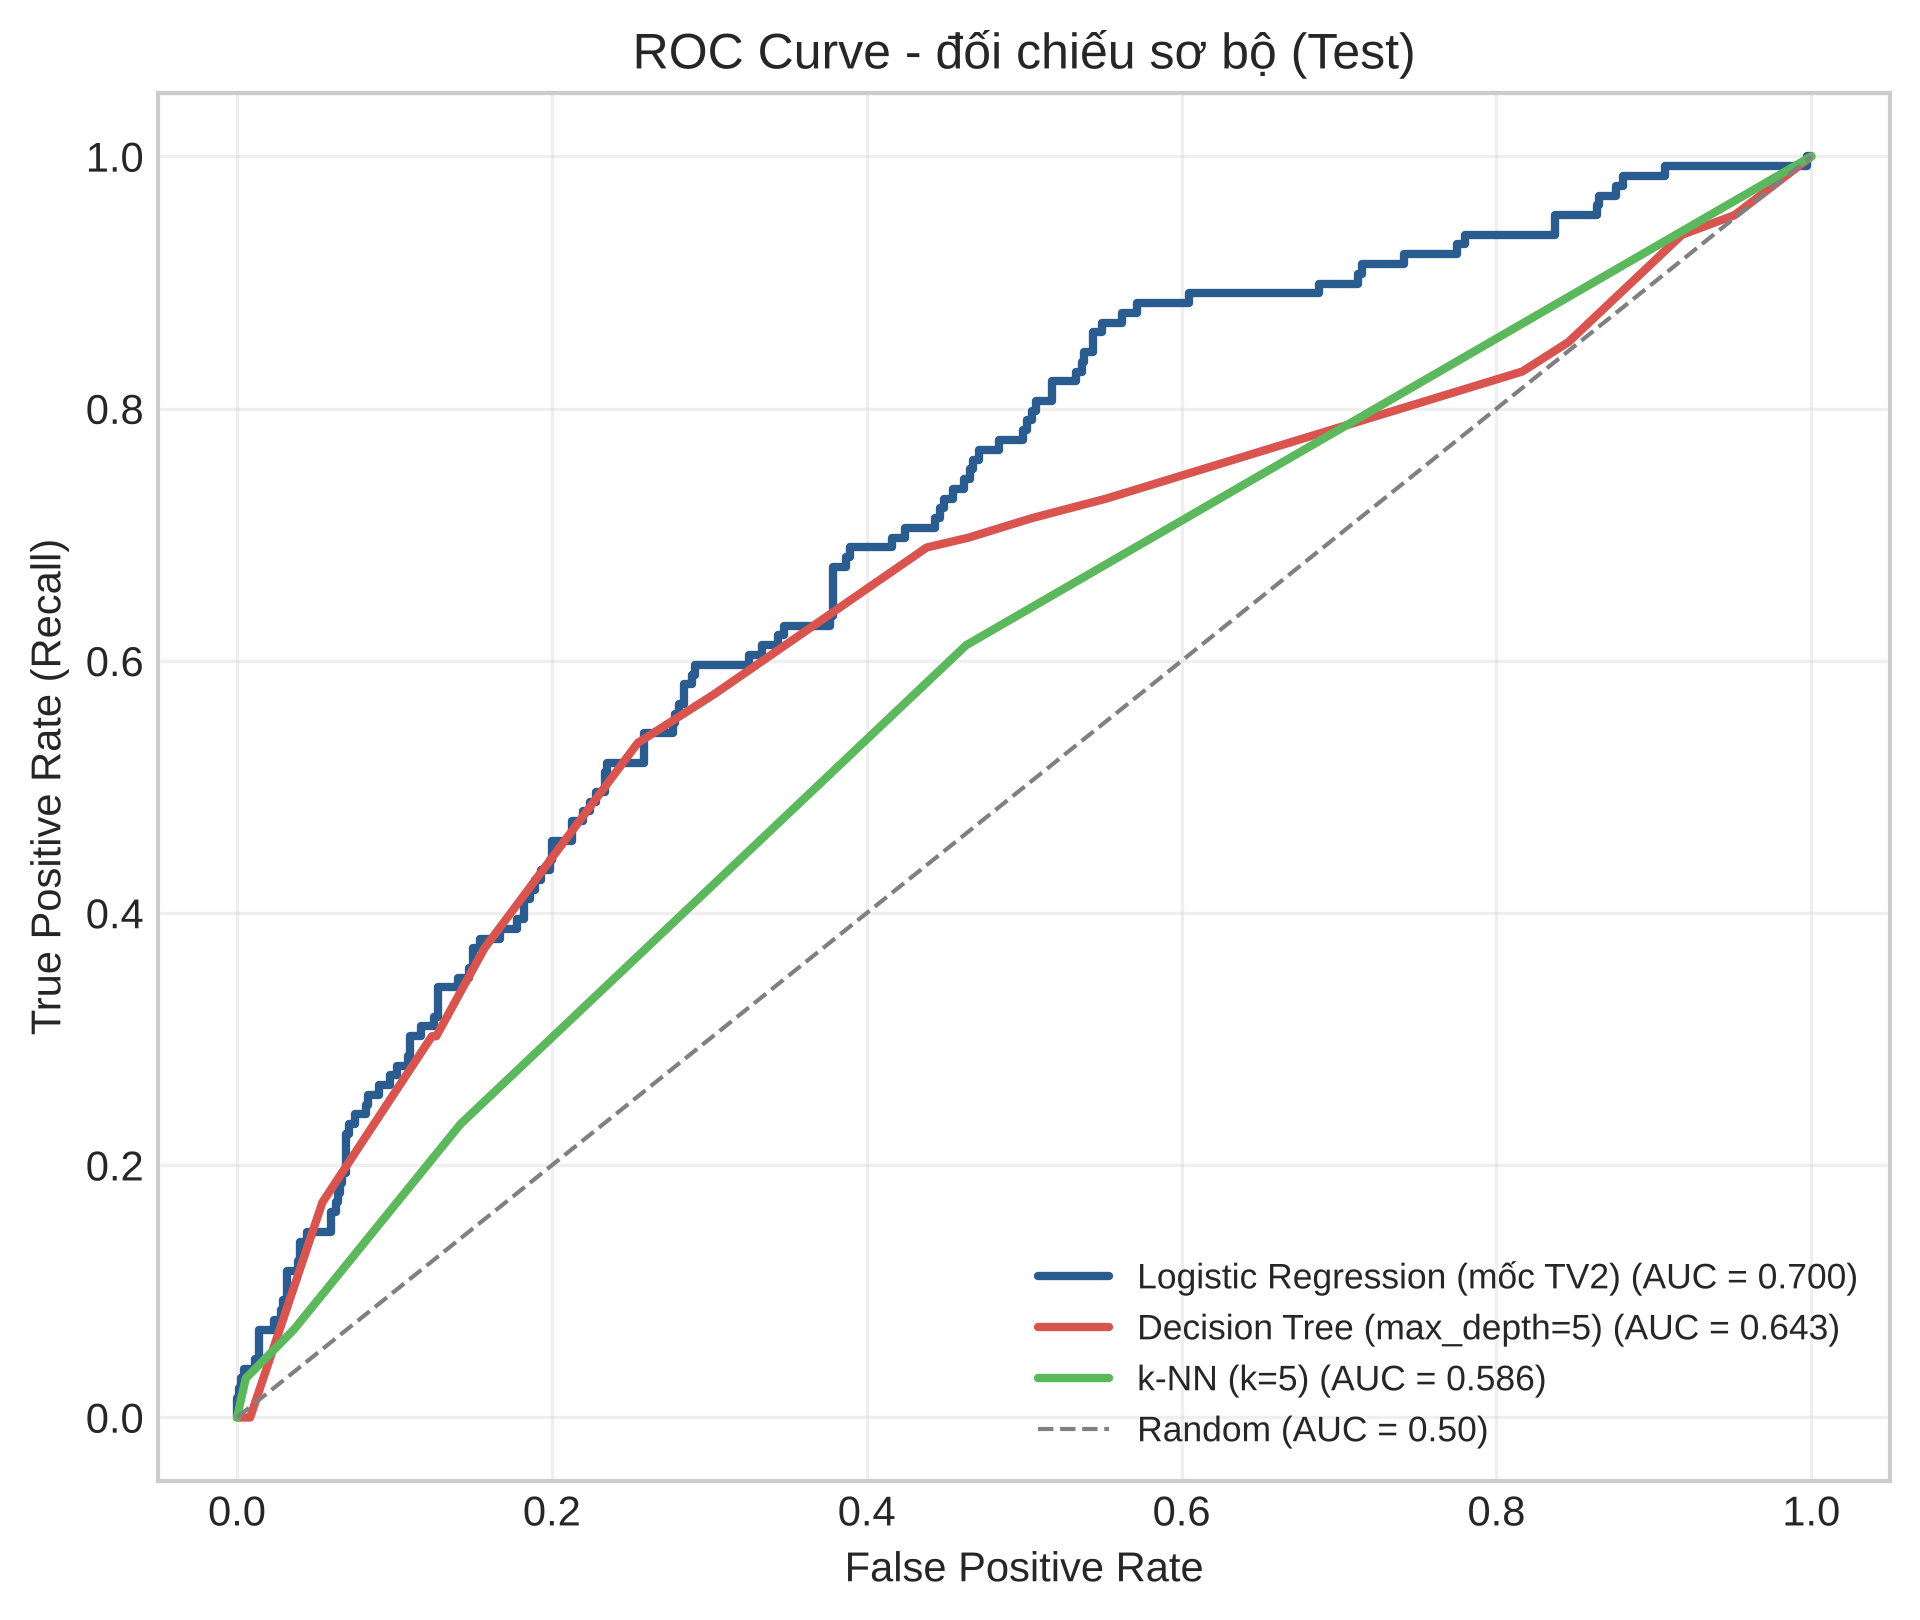

In [20]:
# 3. (TV3) Lưu bảng CSV + Confusion Matrix + ROC so sánh (dpi=300)
os.makedirs('../models/results', exist_ok=True)
tv3_test_part = tv3_test_df[['ROC-AUC', 'Recall', 'F1', 'Precision', 'Accuracy']].add_prefix('Test ').round(4)
tv3_over_part = tv3_test_df[['Train ROC-AUC', 'Gap (Train - Test AUC)']].round(4)
tv3_out = pd.concat([tv3_cv_df, tv3_test_part, tv3_over_part], axis=1)
tv3_out.to_csv('../models/results/early_comparison_tv3.csv')
print('Đã lưu: ../models/results/early_comparison_tv3.csv')

# Confusion Matrix 3 mô hình
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), dpi=300)
for ax, name in zip(axes, tv3_order):
    cm_ = confusion_matrix(y_test, tv3_pred[name]['y_pred'])
    sns.heatmap(cm_, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Dự đoán 0', 'Dự đoán 1'], yticklabels=['Thực tế 0', 'Thực tế 1'])
    ax.set_title(name, fontsize=10)
fig.suptitle('Confusion Matrix - đối chiếu sơ bộ (Test)', fontsize=12)
plt.tight_layout()
fig.savefig('../notebooks/figures/early_confusion_matrices_tv3.png', dpi=300, bbox_inches='tight')
plt.show()

# ROC curve chồng 3 mô hình
fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=300)
for name, col in zip(tv3_order, ['#2b5c8f', '#d9534f', '#5cb85c']):
    fpr_, tpr_, _ = roc_curve(y_test, tv3_pred[name]['y_prob'])
    ax.plot(fpr_, tpr_, lw=2, color=col, label=f"{name} (AUC = {roc_auc_score(y_test, tv3_pred[name]['y_prob']):.3f})")
ax.plot([0, 1], [0, 1], '--', color='gray', lw=1, label='Random (AUC = 0.50)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('ROC Curve - đối chiếu sơ bộ (Test)')
ax.legend(loc='lower right', fontsize=8.5)
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig('../notebooks/figures/early_roc_comparison_tv3.png', dpi=300, bbox_inches='tight')
plt.show()

## Nhận xét đối chiếu sơ bộ (TV3)
1. **Logistic Regression (mốc TV2) vẫn tốt nhất** trên các chỉ số chính ở tập Test: ROC-AUC 0.700 (Decision Tree 0.643, k-NN 0.586) và Recall 0.597 (Decision Tree 0.574, k-NN 0.070).
2. **k-NN có Accuracy cao nhất (0.828) nhưng Recall chỉ 0.070**: mô hình gần như đoán toàn bộ là "không bệnh" do dữ liệu mất cân bằng (~85/15) và k-NN không hỗ trợ `class_weight`. Bỏ sót ~93% người bệnh nên **không phù hợp bài toán y tế**, đây là lý do không dùng Accuracy làm thước đo chính.
3. **Mức overfit** (Train ROC-AUC - Test ROC-AUC): Logistic Regression 0.04, Decision Tree 0.12, k-NN 0.30. Decision Tree đơn lẻ và k-NN overfit rõ hơn mô hình tuyến tính.
4. Đây chỉ là mốc đối chiếu ban đầu (chưa tuning). **Milestone 2** sẽ tối ưu siêu tham số và thử Random Forest / XGBoost để giảm overfitting và so sánh với các mốc này.